In [ ]:
%pip install -q datasets pandas numpy matplotlib psutil

In [ ]:
import psutil
import shutil

ram = psutil.virtual_memory()
disk = shutil.disk_usage("/content")

print("Total RAM:", round(ram.total / 1024**3, 2), "GB")
print("Available RAM:", round(ram.available / 1024**3, 2), "GB")
print("Free storage:", round(disk.free / 1024**3, 2), "GB")

Total RAM: 12.67 GB
Available RAM: 11.56 GB
Free storage: 107.62 GB


In [ ]:
from datasets import load_dataset
from itertools import islice

stream = load_dataset(
    "phreshphish/phreshphish",
    split="train",
    streaming=True
)

for record in islice(stream, 3):
    print({
        "label": record.get("label"),
        "url_length": len(record.get("url") or ""),
        "html_length": len(record.get("html") or "")
    })

README.md:   0%|          | 0.00/4.28k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

{'label': 'benign', 'url_length': 69, 'html_length': 518982}
{'label': 'benign', 'url_length': 33, 'html_length': 192077}
{'label': 'benign', 'url_length': 89, 'html_length': 164883}


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Exists:", PROJECT_DIR.exists())

Project folder: /content/drive/MyDrive/PhreshPhish_Project
Exists: True


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
AUDIT_DIR = PROJECT_DIR / "audit"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Audit directory:", AUDIT_DIR)
print("Ready:", AUDIT_DIR.exists())


Project directory: /content/drive/MyDrive/PhreshPhish_Project
Audit directory: /content/drive/MyDrive/PhreshPhish_Project/audit
Ready: True


In [ ]:

from datasets import load_dataset
from itertools import islice
import pandas as pd
import numpy as np

REPO = "phreshphish/phreshphish"

train_stream = load_dataset(
    REPO,
    split="train",
    streaming=True
)

print("Connected successfully.")
print("Available columns:", list(train_stream.features))


Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Connected successfully.
Available columns: ['sha256', 'url', 'label', 'target', 'date', 'lang', 'lang_score', 'html']


In [ ]:

from urllib.parse import urlsplit
from collections import Counter

def get_hostname(url):
    url = str(url or "").strip()

    if not url:
        return ""

    try:
        # Use a temporary scheme only to parse the hostname.
        parsed_url = (
            url if "://" in url
            else "http://" + url
        )
        return (urlsplit(parsed_url).hostname or "").lower()
    except ValueError:
        return ""


def audit_records(stream, n=500):
    records = []

    for row in islice(stream, n):
        url = str(row.get("url") or "")
        html = str(row.get("html") or "")

        records.append({
            "sha256": row.get("sha256"),
            "url": url,
            "label": row.get("label"),
            "date": row.get("date"),
            "hostname": get_hostname(url),

            "url_length": len(url),
            "html_length": len(html),

            "url_missing": not bool(url.strip()),
            "html_missing": not bool(html.strip()),

            "has_scheme": url.lower().startswith(
                ("http://", "https://")
            ),
            "has_https": url.lower().startswith("https://"),
            "has_query": "?" in url,

            "html_form_count": html.lower().count("<form"),
            "html_script_count": html.lower().count("<script"),
        })

    return pd.DataFrame(records)


In [ ]:

%pip install -q datasets pandas pyarrow

import pandas as pd
import hashlib
import shutil
import gc
from pathlib import Path
from urllib.parse import urlsplit
from datasets import load_dataset

REPO = "phreshphish/phreshphish"

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
AUDIT_DIR = PROJECT_DIR / "audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 5000

print("Audit directory:", AUDIT_DIR)
print("Batch size:", BATCH_SIZE)


Audit directory: /content/drive/MyDrive/PhreshPhish_Project/audit
Batch size: 5000


In [ ]:

def audit_record(row):
    url = str(row.get("url") or "")
    html = str(row.get("html") or "")

    try:
        parsed_url = urlsplit(
            url if "://" in url else "http://" + url
        )
        hostname = (parsed_url.hostname or "").lower()
    except ValueError:
        hostname = ""

    return {
        "sha256": row.get("sha256"),
        "url": url,
        "hostname": hostname,
        "label": row.get("label"),
        "date": row.get("date"),
        "lang": row.get("lang"),
        "lang_score": row.get("lang_score"),

        # Missingness
        "url_missing": int(not bool(url.strip())),
        "html_missing": int(not bool(html.strip())),
        "target_missing": int(
            not bool(str(row.get("target") or "").strip())
        ),

        # URL characteristics
        "url_length": len(url),
        "has_scheme": int(
            url.lower().startswith(("http://", "https://"))
        ),
        "has_https": int(url.lower().startswith("https://")),
        "has_query": int("?" in url),

        # HTML characteristics
        "html_length": len(html),
        "html_form_count": html.lower().count("<form"),
        "html_script_count": html.lower().count("<script"),

        # Exact-content duplicate detection
        "html_sha256": hashlib.sha256(
            html.encode("utf-8", errors="replace")
        ).hexdigest()
    }


In [ ]:

def run_full_audit(split, batch_size=5000):
    split_dir = AUDIT_DIR / split
    split_dir.mkdir(parents=True, exist_ok=True)

    # Completed batches are named by their starting row.
    completed = sorted(split_dir.glob("batch_*.csv.gz"))

    completed_starts = {
        int(p.stem.split(".")[0].split("_")[1])
        for p in completed
    }

    # Find the first incomplete batch.
    start_row = 0
    while start_row in completed_starts:
        start_row += batch_size

    print(f"{split}: starting at row {start_row:,}")

    stream = load_dataset(
        REPO,
        split=split,
        streaming=True
    )

    # Resume from a saved batch boundary.
    # Note: skip() can still incur substantial remote reading.
    if start_row:
        stream = stream.skip(start_row)

    buffer = []
    current_start = start_row
    processed = start_row

    def save_batch(records, batch_start):
        df_batch = pd.DataFrame(records)

        filename = f"batch_{batch_start:09d}.csv.gz"
        local_path = Path("/content") / filename
        drive_path = split_dir / filename

        # Write locally first, then copy a completed file.
        df_batch.to_csv(
            local_path,
            index=False,
            compression="gzip"
        )
        shutil.copy2(local_path, drive_path)
        local_path.unlink()

        return len(df_batch)

    for row in stream:
        buffer.append(audit_record(row))
        processed += 1

        if len(buffer) >= batch_size:
            saved = save_batch(buffer, current_start)

            print(
                f"{split}: {processed:,} records audited",
                flush=True
            )

            current_start += saved
            buffer.clear()
            gc.collect()

    if buffer:
        save_batch(buffer, current_start)
        buffer.clear()

    print(f"{split}: audit complete. Rows processed: {processed:,}")


In [ ]:

run_full_audit("train", BATCH_SIZE)


train: starting at row 0


Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

train: 5,000 records audited
train: 10,000 records audited
train: 15,000 records audited
train: 20,000 records audited
train: 25,000 records audited
train: 30,000 records audited
train: 35,000 records audited
train: 40,000 records audited
train: 45,000 records audited
train: 50,000 records audited
train: 55,000 records audited
train: 60,000 records audited
train: 65,000 records audited
train: 70,000 records audited
train: 75,000 records audited
train: 80,000 records audited
train: 85,000 records audited
train: 90,000 records audited
train: 95,000 records audited
train: 100,000 records audited
train: 105,000 records audited
train: 110,000 records audited
train: 115,000 records audited
train: 120,000 records audited
train: 125,000 records audited
train: 130,000 records audited
train: 135,000 records audited
train: 140,000 records audited
train: 145,000 records audited
train: 150,000 records audited
train: 155,000 records audited
train: 160,000 records audited
train: 165,000 records audit

In [ ]:

run_full_audit("test", BATCH_SIZE)


test: starting at row 0


Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

test: 5,000 records audited
test: 10,000 records audited
test: 15,000 records audited
test: 20,000 records audited
test: 25,000 records audited
test: 30,000 records audited
test: 35,000 records audited
test: 40,000 records audited
test: 45,000 records audited
test: 50,000 records audited
test: 55,000 records audited
test: 60,000 records audited
test: 65,000 records audited
test: 70,000 records audited
test: 75,000 records audited
test: 80,000 records audited
test: 85,000 records audited
test: 90,000 records audited
test: 95,000 records audited
test: 100,000 records audited
test: 105,000 records audited
test: 110,000 records audited
test: 115,000 records audited
test: 120,000 records audited
test: 125,000 records audited
test: 130,000 records audited
test: 135,000 records audited
test: 140,000 records audited
test: 145,000 records audited
test: 150,000 records audited
test: 155,000 records audited
test: 160,000 records audited
test: 165,000 records audited
test: audit complete. Rows pro

In [ ]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project/audit")

def load_audit(split):
    files = sorted((AUDIT_DIR / split).glob("batch_*.csv.gz"))

    if not files:
        raise FileNotFoundError(
            f"No saved audit batches found for {split}"
        )

    print(f"Loading {len(files)} batches for {split}")

    return pd.concat(
        [pd.read_csv(file) for file in files],
        ignore_index=True
    )

train_audit = load_audit("train")
test_audit = load_audit("test")

print("Training rows:", len(train_audit))
print("Testing rows:", len(test_audit))
print("Total rows:", len(train_audit) + len(test_audit))

Loading 100 batches for train
Loading 34 batches for test
Training rows: 498255
Testing rows: 168060
Total rows: 666315


In [ ]:

def load_audit(split):
    files = sorted((AUDIT_DIR / split).glob("batch_*.csv.gz"))

    if not files:
        raise FileNotFoundError(
            f"No audit batches found for {split}"
        )

    return pd.concat(
        [pd.read_csv(p) for p in files],
        ignore_index=True
    )


train_audit = load_audit("train")
test_audit = load_audit("test")

print("Training records:", len(train_audit))
print("Test records:", len(test_audit))
print("Total:", len(train_audit) + len(test_audit))


Training records: 498255
Test records: 168060
Total: 666315


In [ ]:

for name, data in [
    ("TRAIN", train_audit),
    ("TEST", test_audit)
]:
    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)

    print("\nClass counts:")
    print(data["label"].value_counts(dropna=False))

    print("\nClass percentages:")
    print(
        data["label"]
        .value_counts(normalize=True, dropna=False)
        .mul(100).round(2)
    )

    print("\nMissing URL:", data["url_missing"].sum())
    print("Missing HTML:", data["html_missing"].sum())
    print("Missing target brand:", data["target_missing"].sum())
    print("Missing label:", data["label"].isna().sum())

    print("\nDuplicate URL:", data["url"].duplicated().sum())
    print("Duplicate sample ID:", data["sha256"].duplicated().sum())
    print("Duplicate HTML hash:",
          data["html_sha256"].duplicated().sum())

    conflicts = (
        data.groupby("url")["label"].nunique().gt(1).sum()
    )
    print("URLs with conflicting labels:", conflicts)

print("\nCROSS-SPLIT OVERLAP")

for col in ["url", "sha256", "html_sha256", "hostname"]:
    a = set(train_audit[col].dropna()) - {""}
    b = set(test_audit[col].dropna()) - {""}
    print(col, "overlap:", len(a & b))



TRAIN

Class counts:
label
benign    276729
phish     221526
Name: count, dtype: int64

Class percentages:
label
benign    55.54
phish     44.46
Name: proportion, dtype: float64

Missing URL: 0
Missing HTML: 0
Missing target brand: 276644
Missing label: 0

Duplicate URL: 0
Duplicate sample ID: 0
Duplicate HTML hash: 46057
URLs with conflicting labels: 0

TEST

Class counts:
label
benign    91260
phish     76800
Name: count, dtype: int64

Class percentages:
label
benign    54.3
phish     45.7
Name: proportion, dtype: float64

Missing URL: 0
Missing HTML: 0
Missing target brand: 91260
Missing label: 0

Duplicate URL: 0
Duplicate sample ID: 0
Duplicate HTML hash: 30549
URLs with conflicting labels: 0

CROSS-SPLIT OVERLAP
url overlap: 0
sha256 overlap: 0
html_sha256 overlap: 16
hostname overlap: 16217


In [ ]:

numeric_cols = [
    "url_length",
    "html_length",
    "html_form_count",
    "html_script_count"
]

outlier_rows = []

for col in numeric_cols:
    values = train_audit[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (values < lower) | (values > upper)

    outlier_rows.append({
        "feature": col,
        "min": values.min(),
        "median": values.median(),
        "p95": values.quantile(0.95),
        "p99": values.quantile(0.99),
        "max": values.max(),
        "outlier_count": int(mask.sum()),
        "outlier_percent": round(mask.mean() * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)

outlier_report.to_csv(
    AUDIT_DIR / "full_outlier_report.csv",
    index=False
)


,feature,min,median,p95,p99,max,outlier_count,outlier_percent
0,url_length,8,48.0,112.0,175.00,25523,20433,4.10
1,html_length,23,122374.0,1105749.8,2205827.84,76259682,45214,9.07
2,html_form_count,0,1.0,5.0,11.00,1008,20103,4.03
3,html_script_count,0,21.0,113.0,218.00,4364,25311,5.08


In [ ]:

bias_cols = [
    "has_scheme",
    "has_https",
    "has_query",
    "url_missing",
    "html_missing",
    "url_length",
    "html_length",
    "html_form_count",
    "html_script_count"
]

bias_report = (
    train_audit.groupby("label")[bias_cols]
    .mean()
    .T
)

display(bias_report.round(3))

bias_report.to_csv(
    AUDIT_DIR / "collection_bias_report.csv"
)

print("\nScheme presence by class (%):")
display(
    pd.crosstab(
        train_audit["label"],
        train_audit["has_scheme"],
        normalize="index"
    ).mul(100).round(2)
)


label,benign,phish
has_scheme,0.985,1.000
has_https,0.979,0.866
has_query,0.000,0.074
url_missing,0.000,0.000
html_missing,0.000,0.000
url_length,61.047,52.844
html_length,422982.693,122721.786
html_form_count,2.221,0.872
html_script_count,50.919,15.820



Scheme presence by class (%):


has_scheme,0,1
label,,
benign,1.51,98.49
phish,0.00,100.00


In [ ]:
from pathlib import Path

drive_path = Path("/content/drive/MyDrive")
audit_path = drive_path / "PhreshPhish_Project" / "audit"

print("Google Drive accessible:", drive_path.exists())
print("Audit folder exists:", audit_path.exists())

if audit_path.exists():
    print("\nAudit folder contents:")
    for item in audit_path.iterdir():
        print(item.name)

Google Drive accessible: False
Audit folder exists: False


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

batch_files = list(drive_root.rglob("batch_*.csv.gz"))

print("Total batch files found:", len(batch_files))

for file in batch_files[:20]:
    print(file)

Total batch files found: 134
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000000000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000005000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000010000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000015000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000020000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000025000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000030000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000035000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000040000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000045000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000050000.csv.gz
/content/drive/MyDrive/PhreshPhish_Project/audit/train/batch_000055000.csv.gz
/content/drive/MyDrive/PhreshPhish_

In [ ]:
import pandas as pd
from pathlib import Path

# Replace this with the actual folder if different
train_dir = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/audit/train"
)

files = sorted(train_dir.glob("batch_*.csv.gz"))

train_audit = pd.concat(
    [pd.read_csv(f) for f in files],
    ignore_index=True
)

print("Training records recovered:", len(train_audit))

Training records recovered: 498255


In [ ]:
import pandas as pd
from pathlib import Path

# Change this path if your files were found elsewhere.
AUDIT_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/audit"
)

train_files = sorted((AUDIT_DIR / "train").glob("batch_*.csv.gz"))
test_files = sorted((AUDIT_DIR / "test").glob("batch_*.csv.gz"))

print("Training batches:", len(train_files))
print("Testing batches:", len(test_files))

if not train_files:
    raise FileNotFoundError(
        "Training files not found. Update AUDIT_DIR."
    )

train_audit = pd.concat(
    [pd.read_csv(f) for f in train_files],
    ignore_index=True
)

print("Training records:", len(train_audit))

if test_files:
    test_audit = pd.concat(
        [pd.read_csv(f) for f in test_files],
        ignore_index=True
    )
    print("Testing records:", len(test_audit))
else:
    test_audit = None
    print("Test audit not available yet.")

Training batches: 100
Testing batches: 34
Training records: 498255
Testing records: 168060


In [ ]:
columns = [
    "url_length",
    "html_length",
    "html_form_count",
    "html_script_count"
]

for col in columns:
    print("\n" + "=" * 50)
    print(col)
    print("=" * 50)

    display(
        train_audit.groupby("label")[col]
        .describe(
            percentiles=[0.25, 0.50, 0.75, 0.90, 0.99]
        )
        .round(2)
    )


url_length


,count,mean,std,min,25%,50%,75%,90%,99%,max
label,,,,,,,,,,
benign,276729.0,61.05,28.23,8.0,42.0,55.0,74.0,96.0,148.0,1000.0
phish,221526.0,52.84,92.21,12.0,32.0,39.0,59.0,84.0,192.0,25523.0



html_length


,count,mean,std,min,25%,50%,75%,90%,99%,max
label,,,,,,,,,,
benign,276729.0,422982.69,595469.41,23.0,91551.0,250647.0,544526.0,991581.8,2596344.20,45877318.0
phish,221526.0,122721.79,482229.62,28.0,7442.0,36704.5,136252.0,263345.0,1357788.75,76259682.0



html_form_count


,count,mean,std,min,25%,50%,75%,90%,99%,max
label,,,,,,,,,,
benign,276729.0,2.22,6.55,0.0,0.0,1.0,3.0,5.0,14.0,1008.0
phish,221526.0,0.87,2.05,0.0,0.0,0.0,1.0,2.0,6.0,188.0



html_script_count


,count,mean,std,min,25%,50%,75%,90%,99%,max
label,,,,,,,,,,
benign,276729.0,50.92,57.86,0.0,17.0,37.0,67.0,107.0,265.0,4364.0
phish,221526.0,15.82,23.31,0.0,3.0,6.0,21.0,41.0,85.0,1820.0


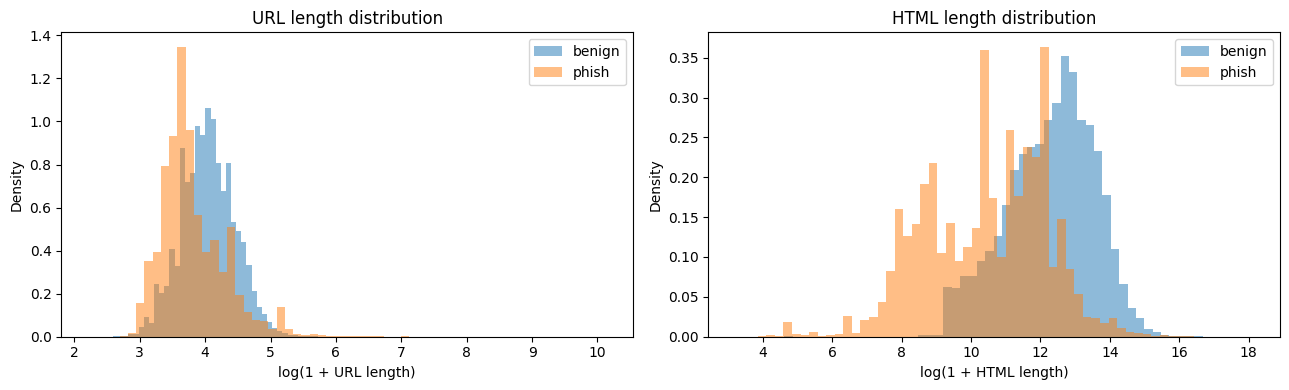

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for label, group in train_audit.groupby("label"):
    axes[0].hist(
        np.log1p(group["url_length"].clip(lower=0)),
        bins=60,
        alpha=0.5,
        density=True,
        label=label
    )

    axes[1].hist(
        np.log1p(group["html_length"].clip(lower=0)),
        bins=60,
        alpha=0.5,
        density=True,
        label=label
    )

axes[0].set_title("URL length distribution")
axes[0].set_xlabel("log(1 + URL length)")

axes[1].set_title("HTML length distribution")
axes[1].set_xlabel("log(1 + HTML length)")

for ax in axes:
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
outlier_results = []

for col in columns:
    values = train_audit[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (values < lower) | (values > upper)

    outlier_results.append({
        "feature": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percent": round(mask.mean() * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_results)
display(outlier_report)

,feature,lower_bound,upper_bound,outlier_count,outlier_percent
0,url_length,-13.50,118.50,20433,4.10
1,html_length,-430367.75,802962.25,45214,9.07
2,html_form_count,-3.00,5.00,20103,4.03
3,html_script_count,-59.50,112.50,25311,5.08


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

diagnostic_df = train_audit[
    ["html_length", "label"]
].dropna()

X = diagnostic_df[["html_length"]]
y = (diagnostic_df["label"] == "phish").astype(int)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

tree = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=100,
    random_state=42
)

tree.fit(X_train, y_train)

y_pred = tree.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_val, y_pred), 4)
)

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_pred))

print("\nClassification report:")
print(classification_report(y_val, y_pred))

Accuracy: 0.7126
Balanced accuracy: 0.7276

Confusion matrix:
[[32785 22561]
 [ 6081 38224]]

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.59      0.70     55346
           1       0.63      0.86      0.73     44305

    accuracy                           0.71     99651
   macro avg       0.74      0.73      0.71     99651
weighted avg       0.75      0.71      0.71     99651



In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

y = (train_audit["label"] == "phish").astype(int)

# Predict phishing if URL does not use HTTPS.
https_rule = (train_audit["has_https"] == 0).astype(int)

# Predict phishing if URL has a query.
query_rule = (train_audit["has_query"] == 1).astype(int)

for name, predictions in [
    ("No-HTTPS rule", https_rule),
    ("Query-present rule", query_rule)
]:
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y, predictions), 4))
    print(
        "Balanced accuracy:",
        round(balanced_accuracy_score(y, predictions), 4)
    )


No-HTTPS rule
Accuracy: 0.603
Balanced accuracy: 0.5562

Query-present rule
Accuracy: 0.5884
Balanced accuracy: 0.5371


In [ ]:
outlier_report.to_csv(
    AUDIT_DIR / "outlier_analysis.csv",
    index=False
)

summary = train_audit.groupby("label")[columns].describe()
summary.to_csv(AUDIT_DIR / "feature_distribution_summary.csv")

print("Reports saved successfully.")

Reports saved successfully.


In [ ]:

features = [
    "url_length",
    "html_length",
    "html_form_count",
    "html_script_count"
]

results = []

for feature in features:
    values = train_audit[feature].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)

    for label, group in train_audit.groupby("label"):
        count = (group[feature] > upper).sum()

        results.append({
            "feature": feature,
            "label": label,
            "total_records": len(group),
            "outlier_count": int(count),
            "outlier_percent": round(
                count / len(group) * 100, 2
            )
        })

class_outliers = pd.DataFrame(results)

display(class_outliers)


,feature,label,total_records,outlier_count,outlier_percent
0,url_length,benign,276729,9654,3.49
1,url_length,phish,221526,10779,4.87
2,html_length,benign,276729,40868,14.77
3,html_length,phish,221526,4346,1.96
4,html_form_count,benign,276729,17157,6.20
5,html_form_count,phish,221526,2946,1.33
6,html_script_count,benign,276729,23995,8.67
7,html_script_count,phish,221526,1316,0.59


In [ ]:

print("Train rows:", len(train_audit))
print("Test rows:", len(test_audit))

# Exact duplicate counts within each split
for name, df in [("TRAIN", train_audit), ("TEST", test_audit)]:
    print(f"\n{name}")

    for col in ["url", "sha256", "html_sha256"]:
        duplicates = df[col].dropna().duplicated().sum()
        print(f"Duplicate {col}:", duplicates)

# Exact overlap across training and test
print("\nCROSS-SPLIT OVERLAP")

for col in ["url", "sha256", "html_sha256", "hostname"]:
    train_values = set(train_audit[col].dropna()) - {""}
    test_values = set(test_audit[col].dropna()) - {""}

    shared = train_values & test_values

    print(f"{col}: {len(shared):,} shared values")


NameError: name 'train_audit' is not defined

In [ ]:
from pathlib import Path

if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

print("Google Drive is accessible.")

Mounted at /content/drive
Google Drive is accessible.


In [ ]:
import pandas as pd
from pathlib import Path

# Search for your saved audit batch files
drive_root = Path("/content/drive/MyDrive")

batch_files = list(drive_root.rglob("batch_*.csv.gz"))

print("Total saved batches found:", len(batch_files))

# Separate training and testing files
train_files = sorted(
    f for f in batch_files if f.parent.name == "train"
)

test_files = sorted(
    f for f in batch_files if f.parent.name == "test"
)

print("Training batches:", len(train_files))
print("Testing batches:", len(test_files))

if train_files:
    train_audit = pd.concat(
        [pd.read_csv(f) for f in train_files],
        ignore_index=True
    )
    print("Training rows:", len(train_audit))
else:
    print("Training audit files not found.")

if test_files:
    test_audit = pd.concat(
        [pd.read_csv(f) for f in test_files],
        ignore_index=True
    )
    print("Testing rows:", len(test_audit))
else:
    print("Testing audit files not found.")

Total saved batches found: 134
Training batches: 100
Testing batches: 34
Training rows: 498255
Testing rows: 168060


In [ ]:
audit_splits = {}

if "train_audit" in globals():
    audit_splits["TRAIN"] = train_audit

if "test_audit" in globals():
    audit_splits["TEST"] = test_audit

for name, df in audit_splits.items():
    print(f"\n{name}: {len(df):,} records")

    for col in ["url", "sha256", "html_sha256"]:
        if col in df.columns:
            print(
                f"Duplicate {col}:",
                df[col].dropna().duplicated().sum()
            )

if "TRAIN" in audit_splits and "TEST" in audit_splits:
    print("\nCROSS-SPLIT OVERLAP")

    for col in ["url", "sha256", "html_sha256", "hostname"]:
        if col in train_audit.columns and col in test_audit.columns:
            a = set(train_audit[col].dropna()) - {""}
            b = set(test_audit[col].dropna()) - {""}

            print(f"{col}: {len(a & b):,} shared values")
else:
    print("\nCross-split overlap requires both train and test audits.")



TRAIN: 498,255 records
Duplicate url: 0
Duplicate sha256: 0
Duplicate html_sha256: 46057

TEST: 168,060 records
Duplicate url: 0
Duplicate sha256: 0
Duplicate html_sha256: 30549

CROSS-SPLIT OVERLAP
url: 0 shared values
sha256: 0 shared values
html_sha256: 16 shared values
hostname: 16,217 shared values


In [ ]:

# Ignore missing hash values
train_hashes = set(
    train_audit["html_sha256"].dropna()
) - {""}

test_hashes = set(
    test_audit["html_sha256"].dropna()
) - {""}

shared_hashes = train_hashes & test_hashes

# Identify all test rows whose HTML appears in training
test_overlap = test_audit[
    test_audit["html_sha256"].isin(shared_hashes)
].copy()

print("Shared distinct HTML hashes:", len(shared_hashes))
print("Affected test records:", len(test_overlap))

print(
    "Percentage of test records affected:",
    round(len(test_overlap) / len(test_audit) * 100, 2),
    "%"
)

print("\nAffected test records by label:")
print(test_overlap["label"].value_counts())

print("\nPercentage affected within each test class:")
display(
    test_audit.assign(
        shared_html=test_audit["html_sha256"].isin(shared_hashes)
    ).groupby("label")["shared_html"]
    .mean().mul(100).round(2)
)


Shared distinct HTML hashes: 16
Affected test records: 490
Percentage of test records affected: 0.29 %

Affected test records by label:
label
phish     450
benign     40
Name: count, dtype: int64

Percentage affected within each test class:


,shared_html
label,
benign,0.04
phish,0.59


In [ ]:

combined = pd.concat(
    [
        train_audit[["html_sha256", "label"]],
        test_audit[["html_sha256", "label"]]
    ],
    ignore_index=True
).dropna(subset=["html_sha256"])

conflicting_hashes = (
    combined.groupby("html_sha256")["label"]
    .nunique()
)

conflicting_hashes = set(
    conflicting_hashes[conflicting_hashes > 1].index
)

print(
    "HTML hashes associated with both labels:",
    len(conflicting_hashes)
)

print(
    "Total records with conflicting HTML:",
    combined["html_sha256"]
    .isin(conflicting_hashes)
    .sum()
)

print(
    "Test records affected:",
    test_audit["html_sha256"]
    .isin(conflicting_hashes)
    .sum()
)


HTML hashes associated with both labels: 15
Total records with conflicting HTML: 105
Test records affected: 17


In [ ]:

top_hashes = (
    train_audit["html_sha256"]
    .value_counts()
    .head(10)
)

rows = []

for hash_value, count in top_hashes.items():
    subset = train_audit[
        train_audit["html_sha256"] == hash_value
    ]

    rows.append({
        "html_hash": hash_value[:16] + "...",
        "train_count": count,
        "test_count": int(
            (test_audit["html_sha256"] == hash_value).sum()
        ),
        "labels": subset["label"].value_counts().to_dict(),
        "html_length": subset["html_length"].iloc[0],
        "unique_hostnames": subset["hostname"].nunique()
    })

top_repeated = pd.DataFrame(rows)
display(top_repeated)


,html_hash,train_count,test_count,labels,html_length,unique_hostnames
0,61eab9ac6b08d4c7...,1014,0,{'phish': 1014},18725,100
1,eb5b8b1e56316bc9...,882,0,{'phish': 882},124,495
2,88005eac6c7cf3e5...,568,0,{'phish': 568},671,400
3,a8411dc747089d18...,501,0,{'phish': 501},48840,450
4,857e6bccc24dcddc...,478,0,{'phish': 478},2835,473
5,2f24234d37e195fb...,379,0,{'phish': 379},4092,93
6,1b54368db390a436...,370,0,{'phish': 370},2354,276
7,f320e7988a64f409...,349,0,{'phish': 349},26571,261
8,e82eab32746edbd2...,262,0,{'phish': 262},20240,206
9,4de267bfa2855c56...,243,0,{'phish': 243},28385,2


In [ ]:

summary = []

for label, group in train_audit.groupby("label"):
    total = len(group)
    unique_html = group["html_sha256"].nunique()

    summary.append({
        "label": label,
        "total_records": total,
        "unique_html_hashes": unique_html,
        "repeated_records": total - unique_html,
        "repeated_percent": round(
            (total - unique_html) / total * 100, 2
        )
    })

html_uniqueness = pd.DataFrame(summary)
display(html_uniqueness)


,label,total_records,unique_html_hashes,repeated_records,repeated_percent
0,benign,276729,275905,824,0.30
1,phish,221526,176303,45223,20.41


In [ ]:

shared = set(train_audit["html_sha256"].dropna()) & set(
    test_audit["html_sha256"].dropna()
)

rows = []

for html_hash in shared:
    tr = train_audit[
        train_audit["html_sha256"] == html_hash
    ]
    te = test_audit[
        test_audit["html_sha256"] == html_hash
    ]

    rows.append({
        "hash": html_hash[:16] + "...",
        "train_records": len(tr),
        "test_records": len(te),
        "train_labels": tr["label"].value_counts().to_dict(),
        "test_labels": te["label"].value_counts().to_dict(),
        "html_length": tr["html_length"].iloc[0],
        "train_hosts": tr["hostname"].nunique(),
        "test_hosts": te["hostname"].nunique()
    })

shared_html_report = pd.DataFrame(rows).sort_values(
    "test_records", ascending=False
)

display(shared_html_report)

shared_html_report.to_csv(
    AUDIT_DIR / "shared_html_report.csv",
    index=False
)


,hash,train_records,test_records,train_labels,test_labels,html_length,train_hosts,test_hosts
9,ca75196e307a2ebc...,8,447,{'phish': 8},{'phish': 447},160,8,401
0,739ae1ff3de4c77e...,27,16,{'benign': 27},{'benign': 16},113252,27,16
5,92568376b48412eb...,1,6,{'phish': 1},{'benign': 6},30846,1,6
7,0e33c0856da104a0...,1,5,{'benign': 1},{'benign': 5},335677,1,1
1,50a8e76816bf2de7...,1,3,{'phish': 1},{'phish': 3},221,1,2
4,960e1b7e6f86ed01...,1,2,{'benign': 1},{'benign': 2},106914,1,1
12,6327f16ff8e4d121...,1,2,{'benign': 1},{'benign': 2},86095,1,2
2,adb87764204a77a0...,1,1,{'benign': 1},{'benign': 1},12422,1,1
6,0c40a65b4f700a73...,2,1,{'benign': 2},{'benign': 1},116667,1,1
3,fe118ca7acca2467...,7,1,{'phish': 7},{'benign': 1},15753,7,1


NameError: name 'AUDIT_DIR' is not defined

In [ ]:

# Short HTML analysis using saved audit metadata

for threshold in [200, 500, 1000, 5000]:
    print(f"\nHTML length <= {threshold} characters")

    result = (
        train_audit.assign(
            short_html=train_audit["html_length"] <= threshold
        )
        .groupby("label")["short_html"]
        .mean()
        .mul(100)
        .round(2)
    )

    display(result)



HTML length <= 200 characters


,short_html
label,
benign,0.04
phish,0.66



HTML length <= 500 characters


,short_html
label,
benign,0.04
phish,0.93



HTML length <= 1000 characters


,short_html
label,
benign,0.05
phish,1.94



HTML length <= 5000 characters


,short_html
label,
benign,0.06
phish,15.87


In [ ]:

# Compare repetition in short versus longer HTML

df = train_audit.copy()

hash_counts = df["html_sha256"].value_counts()

df["html_repeated"] = (
    df["html_sha256"].map(hash_counts) > 1
)

df["short_html"] = df["html_length"] <= 5000

print("Repeated HTML percentage by class and HTML size:")

result = (
    df.groupby(["label", "short_html"])["html_repeated"]
    .agg(["count", "mean"])
    .reset_index()
)

result["mean"] = (result["mean"] * 100).round(2)
result = result.rename(
    columns={"mean": "repeated_html_percent"}
)

display(result)


Repeated HTML percentage by class and HTML size:


,label,short_html,count,repeated_html_percent
0,benign,False,276568,0.37
1,benign,True,161,57.14
2,phish,False,186360,22.18
3,phish,True,35166,40.76


# Feature Extraction


In [ ]:

import pandas as pd
import numpy as np
import re
import math
import ipaddress

from pathlib import Path
from urllib.parse import urlsplit
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
AUDIT_DIR = PROJECT_DIR / "audit"
FEATURE_DIR = PROJECT_DIR / "features"

FEATURE_DIR.mkdir(parents=True, exist_ok=True)

print("Feature output folder:", FEATURE_DIR)



Feature output folder: /content/drive/MyDrive/PhreshPhish_Project/features


In [ ]:

def load_saved_audit(split):
    folder = AUDIT_DIR / split
    files = sorted(folder.glob("batch_*.csv.gz"))

    if not files:
        raise FileNotFoundError(
            f"No saved {split} batches found in {folder}"
        )

    frames = []

    for file in files:
        frames.append(
            pd.read_csv(
                file,
                dtype={
                    "url": "string",
                    "label": "string",
                    "hostname": "string",
                    "sha256": "string",
                    "html_sha256": "string"
                }
            )
        )

    return pd.concat(frames, ignore_index=True)


train_audit = load_saved_audit("train")
test_audit = load_saved_audit("test")

print("Train:", train_audit.shape)
print("Test:", test_audit.shape)


Train: (498255, 18)
Test: (168060, 18)


In [ ]:

RANDOM_STATE = 42
N_TRAIN = 50000
N_TEST = 15000

assert len(train_audit) == 498255, "Training audit is incomplete"
assert len(test_audit) == 168060, "Test audit is incomplete"

def select_sample(df, n, split_name):
    selected_indices, _ = train_test_split(
        np.arange(len(df)),
        train_size=n,
        stratify=df["label"],
        random_state=RANDOM_STATE
    )

    selected_indices = np.sort(selected_indices)

    selected = df.iloc[selected_indices][
        ["url", "label", "hostname", "html_sha256"]
    ].copy()

    selected.insert(0, "source_row", selected_indices)
    selected.insert(1, "split", split_name)

    return selected.reset_index(drop=True)


train_sample = select_sample(
    train_audit, N_TRAIN, "train"
)

test_sample = select_sample(
    test_audit, N_TEST, "test"
)

train_sample.to_csv(
    FEATURE_DIR / "train_selected_records.csv",
    index=False
)

test_sample.to_csv(
    FEATURE_DIR / "test_selected_records.csv",
    index=False
)

print("Selected train:", len(train_sample))
print("Selected test:", len(test_sample))

print("\nTraining label percentages:")
print(
    train_sample["label"]
    .value_counts(normalize=True)
    .mul(100).round(2)
)

print("\nTest label percentages:")
print(
    test_sample["label"]
    .value_counts(normalize=True)
    .mul(100).round(2)
)


Selected train: 50000
Selected test: 15000

Training label percentages:
label
benign    55.54
phish     44.46
Name: proportion, dtype: Float64

Test label percentages:
label
benign    54.3
phish     45.7
Name: proportion, dtype: Float64


In [ ]:

def calculate_entropy(text):
    if not text:
        return 0.0

    probabilities = [
        text.count(ch) / len(text)
        for ch in set(text)
    ]

    return -sum(
        p * math.log2(p)
        for p in probabilities
    )


def is_ip_address(hostname):
    try:
        ipaddress.ip_address(hostname)
        return 1
    except ValueError:
        return 0


def extract_url_features(url):
    url = str(url or "").strip()

    # Exclude original HTTP/HTTPS scheme from measurements.
    # Retain the original URL separately for audits.
    clean = re.sub(
        r"^https?://", "", url, flags=re.IGNORECASE
    )

    # Add a temporary scheme only for parsing.
    try:
        parsed = urlsplit("http://" + clean)
        hostname = (parsed.hostname or "").lower()
        path = parsed.path or ""
        query = parsed.query or ""
        fragment = parsed.fragment or ""
    except ValueError:
        hostname = ""
        path = ""
        query = ""
        fragment = ""

    length = len(clean)
    digits = sum(ch.isdigit() for ch in clean)
    letters = sum(ch.isalpha() for ch in clean)

    special = sum(
        not ch.isalnum()
        for ch in clean
    )

    tokens = [
        t for t in re.split(r"[^A-Za-z0-9]+", clean)
        if t
    ]

    hostname_parts = [
        p for p in hostname.split(".")
        if p
    ]

    return {
        # URL structure
        "url_length": length,
        "hostname_length": len(hostname),
        "path_length": len(path),
        "query_length": len(query),
        "fragment_length": len(fragment),
        "path_depth": len([
            p for p in path.split("/") if p
        ]),
        "subdomain_count": max(
            0, len(hostname_parts) - 2
        ),

        # Character composition
        "digit_count": digits,
        "letter_count": letters,
        "special_char_count": special,
        "dot_count": clean.count("."),
        "hyphen_count": clean.count("-"),
        "underscore_count": clean.count("_"),
        "slash_count": clean.count("/"),
        "at_count": clean.count("@"),
        "percent_count": clean.count("%"),
        "question_count": clean.count("?"),
        "equals_count": clean.count("="),
        "ampersand_count": clean.count("&"),

        # Ratios
        "digit_ratio": digits / max(length, 1),
        "special_char_ratio": special / max(length, 1),

        # Lexical complexity
        "url_entropy": calculate_entropy(clean),
        "token_count": len(tokens),
        "max_token_length": max(
            (len(t) for t in tokens),
            default=0
        ),
        "avg_token_length": (
            sum(len(t) for t in tokens) / len(tokens)
            if tokens else 0
        ),

        # URL patterns
        "hostname_is_ip": is_ip_address(hostname),
        "contains_punycode": int("xn--" in hostname),
        "has_query": int(bool(query)),
    }


In [ ]:

def create_url_feature_dataset(selected_df):
    feature_rows = []

    for i, url in enumerate(selected_df["url"]):
        feature_rows.append(extract_url_features(url))

        if (i + 1) % 10000 == 0:
            print(f"Processed {i + 1:,} URLs")

    features = pd.DataFrame(feature_rows)

    # Preserve row identity and labels for later HTML matching.
    result = pd.concat(
        [
            selected_df[
                ["source_row", "split", "label", "html_sha256"]
            ].reset_index(drop=True),
            features
        ],
        axis=1
    )

    return result


train_url_features = create_url_feature_dataset(train_sample)
test_url_features = create_url_feature_dataset(test_sample)

train_url_features.to_csv(
    FEATURE_DIR / "train_url_features.csv",
    index=False
)

test_url_features.to_csv(
    FEATURE_DIR / "test_url_features.csv",
    index=False
)

print("\nTraining features:", train_url_features.shape)
print("Test features:", test_url_features.shape)

display(train_url_features.head())


Processed 10,000 URLs
Processed 20,000 URLs
Processed 30,000 URLs
Processed 40,000 URLs
Processed 50,000 URLs
Processed 10,000 URLs

Training features: (50000, 32)
Test features: (15000, 32)


,source_row,split,label,html_sha256,url_length,hostname_length,path_length,query_length,fragment_length,path_depth,...,ampersand_count,digit_ratio,special_char_ratio,url_entropy,token_count,max_token_length,avg_token_length,hostname_is_ip,contains_punycode,has_query
0,15,train,phish,f48a97e925af2e1cca426cd65657bc11f4e28846c64c5e...,52,43,9,0,0,1,...,0,0.365385,0.096154,4.494112,6,32,7.833333,0,0,0
1,19,train,benign,5c29d9baa0331d985e6f7664bfea925e9f1ee5aac4449f...,50,10,40,0,0,5,...,0,0.360000,0.160000,4.005295,9,9,4.666667,0,0,0
2,23,train,benign,666421523bf68db9616ff45b0809255b91611e35124de1...,25,10,15,0,0,2,...,0,0.040000,0.200000,4.023465,5,8,4.000000,0,0,0
3,36,train,benign,b26eaa8ec224c08a5b101820824d49da97243b5c177d43...,28,17,11,0,0,2,...,0,0.000000,0.178571,3.896292,5,7,4.600000,0,0,0
4,38,train,benign,b680b5335b746b7abc95201df089c5e06b7e5fe84c18bf...,47,20,27,0,0,3,...,0,0.042553,0.127660,4.314915,7,12,5.857143,0,0,0


In [ ]:

metadata_cols = [
    "source_row", "split", "label", "html_sha256"
]

numeric_cols = [
    c for c in train_url_features.columns
    if c not in metadata_cols
]

print("Number of numerical URL features:", len(numeric_cols))

print("\nMissing values:")
print(
    train_url_features[numeric_cols]
    .isna().sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nConstant features:")
print(
    train_url_features[numeric_cols]
    .columns[
        train_url_features[numeric_cols].nunique() <= 1
    ].tolist()
)

print("\nFeature summary:")
display(
    train_url_features[numeric_cols]
    .describe()
    .T
    .round(3)
)

assert len(train_url_features) == len(train_sample)
assert len(test_url_features) == len(test_sample)

assert train_url_features["source_row"].equals(
    train_sample["source_row"]
)

print("\nFeature extraction completed successfully.")


Number of numerical URL features: 28

Missing values:
url_length            0
hostname_length       0
path_length           0
query_length          0
fragment_length       0
path_depth            0
subdomain_count       0
digit_count           0
letter_count          0
special_char_count    0
dtype: int64

Constant features:
[]

Feature summary:


,count,mean,std,min,25%,50%,75%,max
url_length,50000.0,49.216,37.558,6.000,28.000,40.000,61.000,1707.000
hostname_length,50000.0,20.810,9.196,4.000,15.000,19.000,25.000,88.000
path_length,50000.0,26.520,30.966,0.000,3.000,18.000,40.000,1674.000
query_length,50000.0,1.764,20.220,0.000,0.000,0.000,0.000,1552.000
fragment_length,50000.0,0.053,1.693,0.000,0.000,0.000,0.000,256.000
path_depth,50000.0,1.781,1.728,0.000,1.000,2.000,3.000,140.000
subdomain_count,50000.0,0.906,0.542,0.000,1.000,1.000,1.000,8.000
digit_count,50000.0,3.991,10.484,0.000,0.000,0.000,5.000,414.000
letter_count,50000.0,38.521,28.063,0.000,23.000,32.000,48.000,1551.000
special_char_count,50000.0,6.704,5.252,1.000,4.000,5.000,8.000,160.000



Feature extraction completed successfully.


In [ ]:

print("1. DATASET SHAPES")
print("Train:", train_url_features.shape)
print("Test:", test_url_features.shape)

print("\n2. MISSING VALUES")
print(
    train_url_features[numeric_cols]
    .isna().sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\n3. CONSTANT FEATURES")
print(
    train_url_features[numeric_cols]
    .columns[
        train_url_features[numeric_cols].nunique() <= 1
    ].tolist()
)

print("\n4. FIRST FIVE ROWS")
display(train_url_features.head())


1. DATASET SHAPES


NameError: name 'train_url_features' is not defined

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:

import pandas as pd
from pathlib import Path

FEATURE_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/features"
)

train_path = FEATURE_DIR / "train_url_features.csv"
test_path = FEATURE_DIR / "test_url_features.csv"

print("Training file exists:", train_path.exists())
print("Testing file exists:", test_path.exists())

if train_path.exists() and test_path.exists():
    train_url_features = pd.read_csv(train_path)
    test_url_features = pd.read_csv(test_path)

    print("\nDatasets loaded successfully!")
    print("Train shape:", train_url_features.shape)
    print("Test shape:", test_url_features.shape)
else:
    print("One or both feature files were not found.")


Training file exists: True
Testing file exists: True

Datasets loaded successfully!
Train shape: (50000, 32)
Test shape: (15000, 32)


In [ ]:

metadata_cols = [
    "source_row",
    "split",
    "label",
    "html_sha256"
]

numeric_cols = [
    col for col in train_url_features.columns
    if col not in metadata_cols
]

print("Number of numerical URL features:", len(numeric_cols))


Number of numerical URL features: 28


In [ ]:

print("1. DATASET SHAPES")
print("Train:", train_url_features.shape)
print("Test:", test_url_features.shape)

print("\n2. TOTAL MISSING VALUES")
print("Train:", train_url_features[numeric_cols].isna().sum().sum())
print("Test:", test_url_features[numeric_cols].isna().sum().sum())

print("\n3. CONSTANT FEATURES")
constant_features = [
    col for col in numeric_cols
    if train_url_features[col].nunique(dropna=False) <= 1
]

print(constant_features)

print("\n4. FIRST FIVE ROWS")
display(train_url_features.head())


1. DATASET SHAPES
Train: (50000, 32)
Test: (15000, 32)

2. TOTAL MISSING VALUES
Train: 0
Test: 0

3. CONSTANT FEATURES
[]

4. FIRST FIVE ROWS


,source_row,split,label,html_sha256,url_length,hostname_length,path_length,query_length,fragment_length,path_depth,...,ampersand_count,digit_ratio,special_char_ratio,url_entropy,token_count,max_token_length,avg_token_length,hostname_is_ip,contains_punycode,has_query
0,15,train,phish,f48a97e925af2e1cca426cd65657bc11f4e28846c64c5e...,52,43,9,0,0,1,...,0,0.365385,0.096154,4.494112,6,32,7.833333,0,0,0
1,19,train,benign,5c29d9baa0331d985e6f7664bfea925e9f1ee5aac4449f...,50,10,40,0,0,5,...,0,0.360000,0.160000,4.005295,9,9,4.666667,0,0,0
2,23,train,benign,666421523bf68db9616ff45b0809255b91611e35124de1...,25,10,15,0,0,2,...,0,0.040000,0.200000,4.023465,5,8,4.000000,0,0,0
3,36,train,benign,b26eaa8ec224c08a5b101820824d49da97243b5c177d43...,28,17,11,0,0,2,...,0,0.000000,0.178571,3.896292,5,7,4.600000,0,0,0
4,38,train,benign,b680b5335b746b7abc95201df089c5e06b7e5fe84c18bf...,47,20,27,0,0,3,...,0,0.042553,0.127660,4.314915,7,12,5.857143,0,0,0


In [ ]:

from google.colab import drive
from pathlib import Path

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"

HTML_DIR = FEATURE_DIR / "html_batches"
HTML_DIR.mkdir(parents=True, exist_ok=True)

print("Feature directory:", FEATURE_DIR)
print("HTML checkpoint directory:", HTML_DIR)


# Baseline model training

In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

datasets = {}

for name in ["url", "html", "hybrid"]:
    datasets[name] = {}

    for split in ["train", "test"]:
        path = FEATURE_DIR / f"{split}_{name}_features.csv"

        if not path.exists():
            raise FileNotFoundError(path)

        df = pd.read_csv(path)
        datasets[name][split] = df

        print(f"{name.upper()} {split}: {df.shape}")

print("\nAll feature files loaded.")


Mounted at /content/drive
URL train: (50000, 32)
URL test: (15000, 32)
HTML train: (50000, 23)
HTML test: (15000, 23)
HYBRID train: (50000, 53)
HYBRID test: (15000, 53)

All feature files loaded.


In [ ]:

metadata_cols = {
    "source_row", "split", "label",
    "html_sha256", "sha256",
    "html_parse_failed", "url", "hostname",
    "date", "target", "lang", "lang_score"
}

for name, parts in datasets.items():
    train = parts["train"]
    test = parts["test"]

    print(f"\n{'='*45}")
    print(name.upper())
    print("="*45)

    print("Training:", train.shape)
    print("Testing:", test.shape)
    print("Train labels:", train["label"].value_counts().to_dict())
    print("Test labels:", test["label"].value_counts().to_dict())

    feature_cols = [
        c for c in train.columns
        if c not in metadata_cols
    ]

    print("Feature count:", len(feature_cols))
    print("Missing values:",
          train[feature_cols].isna().sum().sum())
    print("Non-numeric features:",
          train[feature_cols].select_dtypes(
              exclude="number"
          ).columns.tolist())

    assert train["source_row"].is_unique
    assert test["source_row"].is_unique
    assert set(feature_cols).issubset(test.columns)
    assert set(train["label"].dropna().unique()) <= {
        "benign", "phish"
    }



URL
Training: (50000, 32)
Testing: (15000, 32)
Train labels: {'benign': 27770, 'phish': 22230}
Test labels: {'benign': 8145, 'phish': 6855}
Feature count: 28
Missing values: 0
Non-numeric features: []

HTML
Training: (50000, 23)
Testing: (15000, 23)
Train labels: {'benign': 27770, 'phish': 22230}
Test labels: {'benign': 8145, 'phish': 6855}
Feature count: 19
Missing values: 0
Non-numeric features: []

HYBRID
Training: (50000, 53)
Testing: (15000, 53)
Train labels: {'benign': 27770, 'phish': 22230}
Test labels: {'benign': 8145, 'phish': 6855}
Feature count: 49
Missing values: 0
Non-numeric features: ['split_url', 'split_html']


In [ ]:

for split in ["train", "test"]:
    reference = datasets["url"][split][
        ["source_row", "label"]
    ].sort_values("source_row").reset_index(drop=True)

    for name in ["html", "hybrid"]:
        current = datasets[name][split][
            ["source_row", "label"]
        ].sort_values("source_row").reset_index(drop=True)

        assert reference.equals(current), (
            f"{split} records or labels do not match "
            f"between URL and {name}!"
        )

    print(f"{split}: All three feature sets match.")


train: All three feature sets match.
test: All three feature sets match.


In [ ]:

%pip install -q tldextract scikit-learn


In [ ]:

from sklearn.model_selection import GroupShuffleSplit
import tldextract

selected = pd.read_csv(
    FEATURE_DIR / "train_selected_records.csv"
)

selected = selected.sort_values("source_row").reset_index(drop=True)

# Use the bundled public suffix snapshot, without network fetching.
extractor = tldextract.TLDExtract(suffix_list_urls=None)

def registered_domain(host):
    host = str(host or "").lower().strip()
    result = extractor(host)

    return result.top_domain_under_public_suffix or host

selected["domain_group"] = (
    selected["hostname"]
    .fillna("")
    .map(registered_domain)
)

# Missing hostnames should not all become one artificial group.
missing = selected["domain_group"].eq("")
selected.loc[missing, "domain_group"] = (
    "missing_" + selected.loc[missing, "source_row"].astype(str)
)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        selected,
        y=selected["label"],
        groups=selected["domain_group"]
    )
)

train_ids = set(selected.iloc[train_idx]["source_row"])
val_ids = set(selected.iloc[val_idx]["source_row"])

print("Training records:", len(train_ids))
print("Validation records:", len(val_ids))

print("\nTraining classes:")
print(selected.iloc[train_idx]["label"].value_counts(normalize=True))

print("\nValidation classes:")
print(selected.iloc[val_idx]["label"].value_counts(normalize=True))

assert train_ids.isdisjoint(val_ids)


Training records: 40889
Validation records: 9111

Training classes:
label
benign    0.546504
phish     0.453496
Name: proportion, dtype: float64

Validation classes:
label
benign    0.595324
phish     0.404676
Name: proportion, dtype: float64


In [ ]:
for name, parts in datasets.items():
    df = parts["train"]

    print(f"\n{name.upper()}")
    print("Non-numeric columns:")
    print(df.select_dtypes(exclude="number").columns.tolist())


URL
Non-numeric columns:
['split', 'label', 'html_sha256']

HTML
Non-numeric columns:
['split', 'label']

HYBRID
Non-numeric columns:
['split_url', 'label', 'html_sha256', 'split_html']


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Exclude metadata and identifiers from model inputs
exclude_cols = {
    "source_row", "split", "label", "target",
    "sha256", "html_sha256", "html_parse_failed",
    "url", "hostname", "date", "lang", "lang_score"
}

results = []

for name, parts in datasets.items():

    df = parts["train"].copy()

    # Select only numerical predictor columns
    feature_cols = [
        col for col in df.select_dtypes(include="number").columns
        if col not in exclude_cols
    ]

    # Use the previously created domain-grouped split
    tr = df[df["source_row"].isin(train_ids)]
    va = df[df["source_row"].isin(val_ids)]

    X_train = tr[feature_cols]
    X_val = va[feature_cols]

    y_train = (tr["label"] == "phish").astype(int)
    y_val = (va["label"] == "phish").astype(int)

    print(f"\n{'=' * 50}")
    print(f"FEATURE SET: {name.upper()}")
    print(f"Features: {len(feature_cols)}")
    print(f"Training records: {len(X_train)}")
    print(f"Validation records: {len(X_val)}")
    print(f"{'=' * 50}")

    models = {
        "Logistic Regression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                max_iter=1500,
                random_state=42
            )
        ),

        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=5,
                n_jobs=2,
                random_state=42
            )
        ),

        "Linear SVM": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LinearSVC(
                C=1.0,
                max_iter=5000,
                dual=False,
                random_state=42
            )
        ),

        "Gradient Boosting": make_pipeline(
            SimpleImputer(strategy="median"),
            HistGradientBoostingClassifier(
                max_iter=150,
                max_leaf_nodes=31,
                learning_rate=0.1,
                random_state=42
            )
        ),

        "Extra Trees": make_pipeline(
            SimpleImputer(strategy="median"),
            ExtraTreesClassifier(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=5,
                n_jobs=2,
                random_state=42
            )
        )
    }

    for model_name, model in models.items():

        print(f"\nTraining {name} - {model_name}")

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        results.append({
            "feature_set": name,
            "model": model_name,
            "num_features": len(feature_cols),
            "accuracy": accuracy_score(y_val, predictions),
            "balanced_accuracy": balanced_accuracy_score(
                y_val, predictions
            ),
            "precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_val, predictions, zero_division=0
            )
        })

        print(
            f"Accuracy: {results[-1]['accuracy']:.4f} | "
            f"F1: {results[-1]['f1']:.4f}"
        )

# Compare all 15 experiments
results_df = pd.DataFrame(results)

print("\nFINAL BASELINE COMPARISON")
display(
    results_df.sort_values(
        "f1", ascending=False
    ).round(4)
)

# Save results to Google Drive
MODEL_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    MODEL_DIR / "baseline_validation_results.csv",
    index=False
)

print("\nResults saved successfully.")



FEATURE SET: URL
Features: 28
Training records: 40889
Validation records: 9111

Training url - Logistic Regression
Accuracy: 0.7910 | F1: 0.7324

Training url - Random Forest
Accuracy: 0.8477 | F1: 0.7967

Training url - Linear SVM
Accuracy: 0.7789 | F1: 0.7162

Training url - Gradient Boosting
Accuracy: 0.8682 | F1: 0.8264

Training url - Extra Trees
Accuracy: 0.8226 | F1: 0.7624

FEATURE SET: HTML
Features: 19
Training records: 40889
Validation records: 9111

Training html - Logistic Regression
Accuracy: 0.8299 | F1: 0.8139

Training html - Random Forest
Accuracy: 0.9245 | F1: 0.9036

Training html - Linear SVM
Accuracy: 0.8194 | F1: 0.8064

Training html - Gradient Boosting
Accuracy: 0.9240 | F1: 0.9040

Training html - Extra Trees
Accuracy: 0.8693 | F1: 0.8453

FEATURE SET: HYBRID
Features: 47
Training records: 40889
Validation records: 9111

Training hybrid - Logistic Regression
Accuracy: 0.8803 | F1: 0.8574

Training hybrid - Random Forest
Accuracy: 0.9495 | F1: 0.9361

Training

,feature_set,model,num_features,accuracy,balanced_accuracy,precision,recall,f1
13,hybrid,Gradient Boosting,47,0.9561,0.9519,0.9602,0.9300,0.9449
11,hybrid,Random Forest,47,0.9495,0.9439,0.9590,0.9143,0.9361
8,html,Gradient Boosting,19,0.9240,0.9176,0.9253,0.8836,0.9040
6,html,Random Forest,19,0.9245,0.9166,0.9343,0.8750,0.9036
10,hybrid,Logistic Regression,47,0.8803,0.8817,0.8276,0.8893,0.8574
14,hybrid,Extra Trees,47,0.8883,0.8766,0.8990,0.8156,0.8552
12,hybrid,Linear SVM,47,0.8739,0.8760,0.8169,0.8872,0.8506
9,html,Extra Trees,19,0.8693,0.8714,0.8109,0.8828,0.8453
3,url,Gradient Boosting,28,0.8682,0.8533,0.8846,0.7754,0.8264
5,html,Logistic Regression,19,0.8299,0.8442,0.7301,0.9194,0.8139



Results saved successfully.


# Restoring data

In [ ]:

# RESTORE DATA AND TRAIN/VALIDATION SPLIT

%pip install -q tldextract

import pandas as pd
import numpy as np
import tldextract

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

# Google Drive
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load training feature datasets
datasets = {}

for name in ["url", "html", "hybrid"]:
    path = FEATURE_DIR / f"train_{name}_features.csv"

    if not path.exists():
        raise FileNotFoundError(path)

    datasets[name] = {
        "train": pd.read_csv(path)
    }

    print(name.upper(), datasets[name]["train"].shape)

# Load the records used for domain grouping
selected = pd.read_csv(
    FEATURE_DIR / "train_selected_records.csv"
)

selected = selected.sort_values(
    "source_row"
).reset_index(drop=True)

# Registered-domain extraction
extractor = tldextract.TLDExtract(
    suffix_list_urls=None
)

def get_registered_domain(host):
    host = str(host or "").lower().strip()

    if not host or host == "nan":
        return ""

    result = extractor(host)

    return result.top_domain_under_public_suffix or host

selected["domain_group"] = (
    selected["hostname"].map(get_registered_domain)
)

missing = selected["domain_group"].eq("")

selected.loc[missing, "domain_group"] = (
    "missing_" +
    selected.loc[missing, "source_row"].astype(str)
)

# Recreate the SAME split used previously
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        selected,
        y=selected["label"],
        groups=selected["domain_group"]
    )
)

train_ids = set(
    selected.iloc[train_idx]["source_row"]
)

val_ids = set(
    selected.iloc[val_idx]["source_row"]
)

assert train_ids.isdisjoint(val_ids)

print("\nRESTORED SUCCESSFULLY")
print("Training records:", len(train_ids))
print("Validation records:", len(val_ids))
print("Overlap:", len(train_ids & val_ids))


Mounted at /content/drive
URL (50000, 32)
HTML (50000, 23)
HYBRID (50000, 53)

RESTORED SUCCESSFULLY
Training records: 40889
Validation records: 9111
Overlap: 0


In [ ]:

split_df = selected[
    ["source_row", "label", "domain_group"]
].copy()

split_df["partition"] = np.where(
    split_df["source_row"].isin(train_ids),
    "train",
    "validation"
)

split_path = MODEL_DIR / "train_validation_split.csv"

split_df.to_csv(split_path, index=False)

print("Saved:", split_path)


Saved: /content/drive/MyDrive/PhreshPhish_Project/models/train_validation_split.csv


In [ ]:
split_df = pd.read_csv(
    MODEL_DIR / "train_validation_split.csv"
)

train_ids = set(
    split_df.loc[
        split_df["partition"] == "train",
        "source_row"
    ]
)

val_ids = set(
    split_df.loc[
        split_df["partition"] == "validation",
        "source_row"
    ]
)

# Feature Selection

In [ ]:

import pandas as pd
import numpy as np

from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# These variables must already exist from baseline training:
# datasets, train_ids, val_ids, MODEL_DIR

exclude_cols = {
    "source_row", "split", "label", "target",
    "sha256", "html_sha256", "html_parse_failed",
    "url", "hostname", "date", "lang", "lang_score"
}

print("Feature selection setup ready.")

print("Training IDs:", len(train_ids))
print("Validation IDs:", len(val_ids))
print("Shared IDs:", len(train_ids & val_ids))

assert train_ids.isdisjoint(val_ids)


Feature selection setup ready.
Training IDs: 40889
Validation IDs: 9111
Shared IDs: 0


In [ ]:

mi_rankings = {}
prepared_data = {}

for name, parts in datasets.items():

    df = parts["train"].copy()

    feature_cols = [
        col for col in df.select_dtypes(include="number").columns
        if col not in exclude_cols
    ]

    tr = df[df["source_row"].isin(train_ids)].copy()
    va = df[df["source_row"].isin(val_ids)].copy()

    X_train = tr[feature_cols]
    X_val = va[feature_cols]

    y_train = (tr["label"] == "phish").astype(int)
    y_val = (va["label"] == "phish").astype(int)

    assert len(X_train) > 0
    assert len(X_val) > 0
    assert X_train.columns.tolist() == X_val.columns.tolist()

    # Fit imputation only on training records
    imputer = SimpleImputer(strategy="median")

    X_train_imp = pd.DataFrame(
        imputer.fit_transform(X_train),
        columns=feature_cols,
        index=X_train.index
    )

    # Mark binary indicators as discrete for MI
    discrete_mask = np.array([
        X_train_imp[col].nunique() <= 2
        for col in feature_cols
    ])

    mi_scores = mutual_info_classif(
        X_train_imp,
        y_train,
        discrete_features=discrete_mask,
        random_state=42,
        n_neighbors=3
    )

    ranking = (
        pd.DataFrame({
            "feature": feature_cols,
            "mi_score": mi_scores
        })
        .sort_values(
            "mi_score",
            ascending=False
        )
        .reset_index(drop=True)
    )

    mi_rankings[name] = ranking

    prepared_data[name] = {
        "X_train": X_train,
        "X_val": X_val,
        "y_train": y_train,
        "y_val": y_val
    }

    ranking.to_csv(
        MODEL_DIR / f"{name}_mi_ranking.csv",
        index=False
    )

    print(f"\n{'=' * 50}")
    print(f"{name.upper()} — {len(feature_cols)} FEATURES")
    print("=" * 50)

    display(ranking.head(15))



URL — 28 FEATURES


,feature,mi_score
0,path_length,0.258848
1,slash_count,0.212538
2,path_depth,0.192021
3,hostname_length,0.156062
4,url_entropy,0.147531
5,avg_token_length,0.112408
6,special_char_ratio,0.106857
7,token_count,0.100448
8,url_length,0.100219
9,letter_count,0.092646



HTML — 19 FEATURES


,feature,mi_score
0,html_link_count,0.281433
1,html_tag_count,0.273573
2,html_absolute_link_count,0.260937
3,html_length,0.250546
4,html_relative_link_count,0.247226
5,html_text_length,0.225532
6,html_script_count,0.170070
7,html_image_count,0.163795
8,html_button_count,0.161985
9,html_iframe_count,0.140000



HYBRID — 47 FEATURES


,feature,mi_score
0,html_link_count,0.281776
1,html_tag_count,0.273224
2,path_length,0.260078
3,html_absolute_link_count,0.258239
4,html_length,0.250908
5,html_relative_link_count,0.246063
6,html_text_length,0.225716
7,slash_count,0.210069
8,path_depth,0.188890
9,html_script_count,0.169983


In [ ]:

k_values = {
    "url": [5, 10, 15, 20, 25, 28],
    "html": [5, 10, 15, 19],
    "hybrid": [5, 10, 15, 20, 30, 40, 47]
}

selection_results = []

for name in ["url", "html", "hybrid"]:

    ranking = mi_rankings[name]
    data = prepared_data[name]

    X_train = data["X_train"]
    X_val = data["X_val"]
    y_train = data["y_train"]
    y_val = data["y_val"]

    print(f"\n{'=' * 50}")
    print(f"FEATURE SET: {name.upper()}")
    print("=" * 50)

    for k in k_values[name]:

        selected_features = (
            ranking["feature"]
            .head(k)
            .tolist()
        )

        model = make_pipeline(
            SimpleImputer(strategy="median"),
            HistGradientBoostingClassifier(
                max_iter=150,
                max_leaf_nodes=31,
                learning_rate=0.1,
                random_state=42
            )
        )

        model.fit(
            X_train[selected_features],
            y_train
        )

        predictions = model.predict(
            X_val[selected_features]
        )

        result = {
            "feature_set": name,
            "num_features": k,
            "accuracy": accuracy_score(
                y_val, predictions
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_val, predictions
            ),
            "precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_val, predictions, zero_division=0
            )
        }

        selection_results.append(result)

        print(
            f"Top {k:2d} features | "
            f"Accuracy: {result['accuracy']:.4f} | "
            f"F1: {result['f1']:.4f}"
        )

selection_df = pd.DataFrame(selection_results)

print("\nFINAL MUTUAL INFORMATION COMPARISON")

display(
    selection_df.sort_values(
        ["feature_set", "num_features"]
    ).round(4)
)

selection_df.to_csv(
    MODEL_DIR / "mi_feature_selection_results.csv",
    index=False
)

print("\nResults saved successfully.")



FEATURE SET: URL
Top  5 features | Accuracy: 0.8274 | F1: 0.7745
Top 10 features | Accuracy: 0.8392 | F1: 0.7911
Top 15 features | Accuracy: 0.8593 | F1: 0.8126
Top 20 features | Accuracy: 0.8610 | F1: 0.8149
Top 25 features | Accuracy: 0.8684 | F1: 0.8265
Top 28 features | Accuracy: 0.8682 | F1: 0.8264

FEATURE SET: HTML
Top  5 features | Accuracy: 0.8842 | F1: 0.8556
Top 10 features | Accuracy: 0.9113 | F1: 0.8885
Top 15 features | Accuracy: 0.9183 | F1: 0.8969
Top 19 features | Accuracy: 0.9240 | F1: 0.9040

FEATURE SET: HYBRID
Top  5 features | Accuracy: 0.9021 | F1: 0.8760
Top 10 features | Accuracy: 0.9294 | F1: 0.9119
Top 15 features | Accuracy: 0.9484 | F1: 0.9354
Top 20 features | Accuracy: 0.9518 | F1: 0.9399
Top 30 features | Accuracy: 0.9545 | F1: 0.9431
Top 40 features | Accuracy: 0.9571 | F1: 0.9463
Top 47 features | Accuracy: 0.9561 | F1: 0.9449

FINAL MUTUAL INFORMATION COMPARISON


,feature_set,num_features,accuracy,balanced_accuracy,precision,recall,f1
6,html,5,0.8842,0.8783,0.8637,0.8476,0.8556
7,html,10,0.9113,0.9052,0.9045,0.8731,0.8885
8,html,15,0.9183,0.9119,0.9167,0.8779,0.8969
9,html,19,0.9240,0.9176,0.9253,0.8836,0.9040
10,hybrid,5,0.9021,0.8945,0.8983,0.8549,0.8760
11,hybrid,10,0.9294,0.9250,0.9218,0.9021,0.9119
12,hybrid,15,0.9484,0.9444,0.9479,0.9232,0.9354
13,hybrid,20,0.9518,0.9486,0.9484,0.9317,0.9399
14,hybrid,30,0.9545,0.9509,0.9542,0.9322,0.9431
15,hybrid,40,0.9571,0.9534,0.9591,0.9338,0.9463



Results saved successfully.


In [ ]:

import pandas as pd
from pathlib import Path

MODEL_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project/models")

results_path = MODEL_DIR / "mi_feature_selection_results.csv"

print("File exists:", results_path.exists())

if results_path.exists():
    selection_df = pd.read_csv(results_path)

    print("MI results loaded successfully!")
    print("Number of experiments:", len(selection_df))
    display(selection_df.head())
else:
    print("MI results file not found.")
    print("Check whether MI Step 3 completed and saved its results.")


File exists: True
MI results loaded successfully!
Number of experiments: 17


,feature_set,num_features,accuracy,balanced_accuracy,precision,recall,f1
0,url,5,0.827352,0.812219,0.821277,0.732845,0.774545
1,url,10,0.839205,0.825302,0.834035,0.752373,0.791102
2,url,15,0.859291,0.842388,0.881383,0.753729,0.812573
3,url,20,0.861047,0.844167,0.884164,0.755628,0.814858
4,url,25,0.868401,0.853340,0.886096,0.774342,0.826458


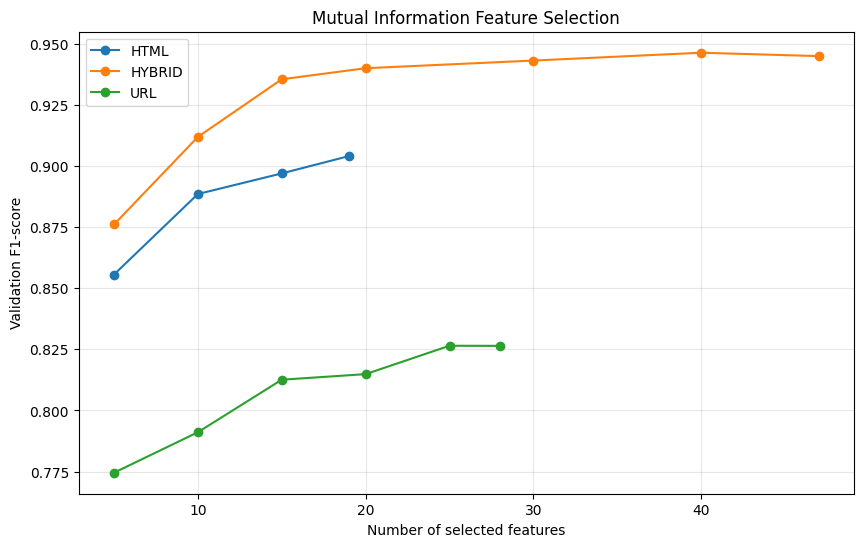

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, group in selection_df.groupby("feature_set"):
    group = group.sort_values("num_features")

    plt.plot(
        group["num_features"],
        group["f1"],
        marker="o",
        label=name.upper()
    )

plt.xlabel("Number of selected features")
plt.ylabel("Validation F1-score")
plt.title("Mutual Information Feature Selection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


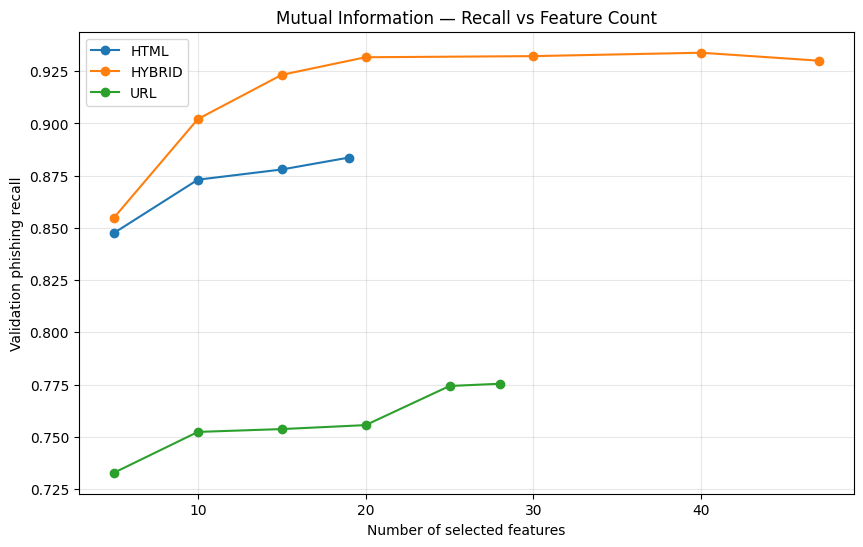

In [ ]:

plt.figure(figsize=(10, 6))

for name, group in selection_df.groupby("feature_set"):
    group = group.sort_values("num_features")

    plt.plot(
        group["num_features"],
        group["recall"],
        marker="o",
        label=name.upper()
    )

plt.xlabel("Number of selected features")
plt.ylabel("Validation phishing recall")
plt.title("Mutual Information — Recall vs Feature Count")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:


from google.colab import drive
from pathlib import Path

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Google Drive connected.")
print("Feature folder exists:", FEATURE_DIR.exists())
print("Model folder:", MODEL_DIR)


Mounted at /content/drive
Google Drive connected.
Feature folder exists: True
Model folder: /content/drive/MyDrive/PhreshPhish_Project/models


In [ ]:

import pandas as pd
import numpy as np

hybrid_df = pd.read_csv(
    FEATURE_DIR / "train_hybrid_features.csv"
)

split_path = MODEL_DIR / "train_validation_split.csv"

if not split_path.exists():
    raise FileNotFoundError(
        "Saved train/validation split not found. "
        "Restore the original domain-grouped split before continuing."
    )

split_df = pd.read_csv(split_path)

train_ids = set(
    split_df.loc[
        split_df["partition"] == "train", "source_row"
    ]
)

val_ids = set(
    split_df.loc[
        split_df["partition"] == "validation", "source_row"
    ]
)

assert train_ids.isdisjoint(val_ids)

print("Hybrid data:", hybrid_df.shape)
print("Training IDs:", len(train_ids))
print("Validation IDs:", len(val_ids))

assert set(hybrid_df["source_row"]) == train_ids | val_ids


Hybrid data: (50000, 53)
Training IDs: 40889
Validation IDs: 9111


In [ ]:

from sklearn.impute import SimpleImputer

exclude_cols = {
    "source_row", "split", "label", "target",
    "sha256", "html_sha256", "html_parse_failed",
    "url", "hostname", "date", "lang", "lang_score"
}

feature_cols = [
    col for col in hybrid_df.select_dtypes(
        include="number"
    ).columns
    if col not in exclude_cols
]

train_df = hybrid_df[
    hybrid_df["source_row"].isin(train_ids)
].copy()

val_df = hybrid_df[
    hybrid_df["source_row"].isin(val_ids)
].copy()

X_train = train_df[feature_cols]
X_val = val_df[feature_cols]

y_train = (train_df["label"] == "phish").astype(int)
y_val = (val_df["label"] == "phish").astype(int)

print("Number of features:", len(feature_cols))
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

assert len(feature_cols) == 47, (
    f"Expected 47 features, found {len(feature_cols)}. "
    "Check whether metadata or duplicate columns are included."
)

assert X_train.columns.equals(X_val.columns)


Number of features: 47
Training shape: (40889, 47)
Validation shape: (9111, 47)


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

hybrid_model = make_pipeline(
    SimpleImputer(strategy="median"),
    HistGradientBoostingClassifier(
        max_iter=150,
        max_leaf_nodes=31,
        learning_rate=0.1,
        random_state=42
    )
)

hybrid_model.fit(X_train, y_train)

val_predictions = hybrid_model.predict(X_val)

print("VALIDATION RESULTS")
print("Accuracy:", round(
    accuracy_score(y_val, val_predictions), 4
))
print("Precision:", round(
    precision_score(y_val, val_predictions), 4
))
print("Recall:", round(
    recall_score(y_val, val_predictions), 4
))
print("F1:", round(
    f1_score(y_val, val_predictions), 4
))
print("\nConfusion matrix:")
print(confusion_matrix(y_val, val_predictions))


VALIDATION RESULTS
Accuracy: 0.9561
Precision: 0.9602
Recall: 0.93
F1: 0.9449

Confusion matrix:
[[5282  142]
 [ 258 3429]]


In [ ]:

from sklearn.inspection import permutation_importance

print("Calculating permutation importance...")

perm = permutation_importance(
    estimator=hybrid_model,
    X=X_val,
    y=y_val,
    scoring={
        "recall": "recall",
        "f1": "f1"
    },
    n_repeats=5,
    random_state=42,
    n_jobs=2
)

perm_ranking = pd.DataFrame({
    "feature": feature_cols,
    "recall_importance": perm["recall"].importances_mean,
    "recall_std": perm["recall"].importances_std,
    "f1_importance": perm["f1"].importances_mean,
    "f1_std": perm["f1"].importances_std
})

perm_ranking = (
    perm_ranking
    .sort_values(
        "recall_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Top 20 features by recall importance:")
display(perm_ranking.head(20))

perm_ranking.to_csv(
    MODEL_DIR / "hybrid_permutation_importance.csv",
    index=False
)

print("Permutation importance saved.")


Calculating permutation importance...
Top 20 features by recall importance:


,feature,recall_importance,recall_std,f1_importance,f1_std
0,path_length,0.076159,0.002741,0.081721,0.003637
1,html_length,0.039924,0.002239,0.039439,0.001976
2,html_relative_link_count,0.024790,0.002214,0.013639,0.001618
3,subdomain_count,0.017684,0.002348,0.021808,0.001974
4,html_absolute_link_count,0.016653,0.002343,0.016587,0.001167
5,html_script_count,0.014104,0.001284,0.021403,0.001534
6,html_link_count,0.011337,0.001049,0.007151,0.000951
7,slash_count,0.011174,0.001408,0.005972,0.001245
8,html_iframe_count,0.010903,0.001090,0.007643,0.000660
9,hostname_length,0.010686,0.002483,0.011269,0.000779


Permutation importance saved.


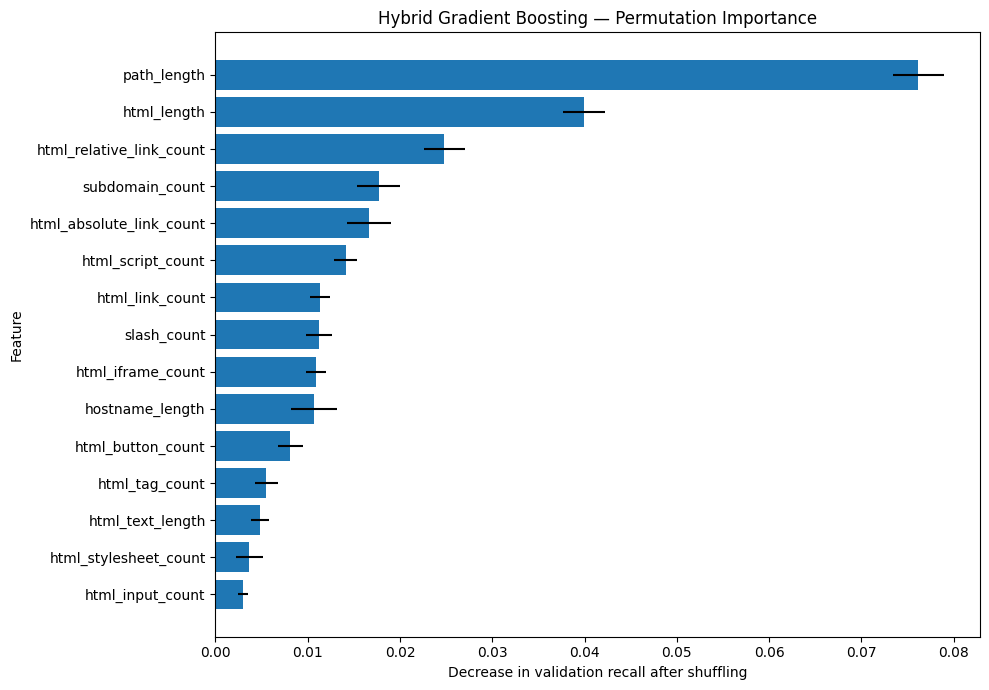

In [ ]:

import matplotlib.pyplot as plt

top = (
    perm_ranking.head(15)
    .sort_values("recall_importance")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top["feature"],
    top["recall_importance"],
    xerr=top["recall_std"]
)

plt.xlabel("Decrease in validation recall after shuffling")
plt.ylabel("Feature")
plt.title("Hybrid Gradient Boosting — Permutation Importance")

plt.tight_layout()
plt.show()


In [ ]:

mi_path = MODEL_DIR / "hybrid_mi_ranking.csv"

if not mi_path.exists():
    raise FileNotFoundError(
        "Hybrid MI ranking not found in the models folder."
    )

mi_ranking = pd.read_csv(mi_path)

comparison = mi_ranking.merge(
    perm_ranking,
    on="feature",
    how="inner"
)

comparison["mi_rank"] = (
    comparison["mi_score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison["permutation_rank"] = (
    comparison["recall_importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison = comparison.sort_values("permutation_rank")

display(
    comparison[
        [
            "feature",
            "mi_score",
            "mi_rank",
            "recall_importance",
            "permutation_rank"
        ]
    ].head(20)
)

comparison.to_csv(
    MODEL_DIR / "mi_vs_permutation_comparison.csv",
    index=False
)

print("Comparison saved.")


,feature,mi_score,mi_rank,recall_importance,permutation_rank
2,path_length,0.260078,3,0.076159,1
4,html_length,0.250908,5,0.039924,2
5,html_relative_link_count,0.246063,6,0.024790,3
40,subdomain_count,0.005049,41,0.017684,4
3,html_absolute_link_count,0.258239,4,0.016653,5
9,html_script_count,0.169983,10,0.014104,6
0,html_link_count,0.281776,1,0.011337,7
7,slash_count,0.210069,8,0.011174,8
14,html_iframe_count,0.141556,15,0.010903,9
12,hostname_length,0.154552,13,0.010686,10


Comparison saved.


In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load hybrid training features
hybrid_df = pd.read_csv(
    FEATURE_DIR / "train_hybrid_features.csv"
)

# Load the SAME train/validation split used previously
split_df = pd.read_csv(
    MODEL_DIR / "train_validation_split.csv"
)

train_ids = set(
    split_df.loc[
        split_df["partition"] == "train", "source_row"
    ]
)

val_ids = set(
    split_df.loc[
        split_df["partition"] == "validation", "source_row"
    ]
)

assert train_ids.isdisjoint(val_ids)
assert set(hybrid_df["source_row"]) == train_ids | val_ids

exclude_cols = {
    "source_row", "split", "label", "target",
    "sha256", "html_sha256", "html_parse_failed",
    "url", "hostname", "date", "lang", "lang_score"
}

feature_cols = [
    c for c in hybrid_df.select_dtypes(include="number").columns
    if c not in exclude_cols
]

tr = hybrid_df[
    hybrid_df["source_row"].isin(train_ids)
].copy()

va = hybrid_df[
    hybrid_df["source_row"].isin(val_ids)
].copy()

X_train = tr[feature_cols]
X_val = va[feature_cols]

y_train = (tr["label"] == "phish").astype(int)
y_val = (va["label"] == "phish").astype(int)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Total hybrid features:", len(feature_cols))

assert len(feature_cols) == 47


Training records: 40889
Validation records: 9111
Total hybrid features: 47


In [ ]:

ablation_groups = {
    "Baseline (all features)": [],

    "Remove HTML size": [
        "html_length",
        "html_text_length",
        "html_tag_count"
    ],

    "Remove URL path": [
        "path_length",
        "slash_count",
        "path_depth"
    ],

    "Remove HTML resources": [
        "html_script_count",
        "html_link_count",
        "html_absolute_link_count",
        "html_relative_link_count",
        "html_stylesheet_count",
        "html_image_count"
    ],

    "Remove URL query": [
        "has_query",
        "query_length",
        "question_count",
        "equals_count",
        "ampersand_count"
    ],

    "Remove all flagged groups": [
        "html_length",
        "html_text_length",
        "html_tag_count",
        "path_length",
        "slash_count",
        "path_depth",
        "html_script_count",
        "html_link_count",
        "html_absolute_link_count",
        "html_relative_link_count",
        "html_stylesheet_count",
        "html_image_count",
        "has_query",
        "query_length",
        "question_count",
        "equals_count",
        "ampersand_count"
    ]
}

for experiment, removed in ablation_groups.items():
    present = [f for f in removed if f in feature_cols]
    missing = [f for f in removed if f not in feature_cols]

    print(
        f"{experiment}: removing {len(present)} features, "
        f"keeping {len(feature_cols) - len(present)}"
    )

    if missing:
        print("  Not found:", missing)


Baseline (all features): removing 0 features, keeping 47
Remove HTML size: removing 3 features, keeping 44
Remove URL path: removing 3 features, keeping 44
Remove HTML resources: removing 6 features, keeping 41
Remove URL query: removing 5 features, keeping 42
Remove all flagged groups: removing 17 features, keeping 30


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

ablation_results = []

for experiment, removed_features in ablation_groups.items():

    selected_features = [
        col for col in feature_cols
        if col not in removed_features
    ]

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=150,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        )
    )

    model.fit(
        X_train[selected_features],
        y_train
    )

    predictions = model.predict(
        X_val[selected_features]
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn) if (fp + tn) else 0.0

    ablation_results.append({
        "experiment": experiment,
        "num_features": len(selected_features),
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "fpr": fpr,
        "false_negatives": int(fn),
        "false_positives": int(fp)
    })

    print(
        f"{experiment} | "
        f"Features: {len(selected_features)} | "
        f"Recall: {ablation_results[-1]['recall']:.4f} | "
        f"F1: {ablation_results[-1]['f1']:.4f} | "
        f"FPR: {fpr:.4f}"
    )

ablation_df = pd.DataFrame(ablation_results)

print("\nFEATURE-ABLATION COMPARISON")

display(
    ablation_df.round(4)
)

ablation_df.to_csv(
    MODEL_DIR / "hybrid_feature_ablation_results.csv",
    index=False
)

print("\nResults saved to Google Drive.")


Baseline (all features) | Features: 47 | Recall: 0.9300 | F1: 0.9449 | FPR: 0.0262
Remove HTML size | Features: 44 | Recall: 0.9165 | F1: 0.9350 | FPR: 0.0299
Remove URL path | Features: 44 | Recall: 0.9341 | F1: 0.9485 | FPR: 0.0242
Remove HTML resources | Features: 41 | Recall: 0.9162 | F1: 0.9312 | FPR: 0.0350
Remove URL query | Features: 42 | Recall: 0.9295 | F1: 0.9433 | FPR: 0.0280
Remove all flagged groups | Features: 30 | Recall: 0.8359 | F1: 0.8749 | FPR: 0.0509

FEATURE-ABLATION COMPARISON


,experiment,num_features,accuracy,balanced_accuracy,precision,recall,f1,fpr,false_negatives,false_positives
0,Baseline (all features),47,0.9561,0.9519,0.9602,0.9300,0.9449,0.0262,258,142
1,Remove HTML size,44,0.9484,0.9433,0.9543,0.9165,0.9350,0.0299,308,162
2,Remove URL path,44,0.9590,0.9550,0.9634,0.9341,0.9485,0.0242,243,131
3,Remove HTML resources,41,0.9452,0.9406,0.9467,0.9162,0.9312,0.0350,309,190
4,Remove URL query,42,0.9548,0.9507,0.9575,0.9295,0.9433,0.0280,260,152
5,Remove all flagged groups,30,0.9033,0.8925,0.9178,0.8359,0.8749,0.0509,605,276



Results saved to Google Drive.


In [ ]:

baseline = ablation_df.loc[
    ablation_df["experiment"] == "Baseline (all features)"
].iloc[0]

comparison_df = ablation_df.copy()

comparison_df["recall_change_pp"] = (
    comparison_df["recall"] - baseline["recall"]
) * 100

comparison_df["f1_change_pp"] = (
    comparison_df["f1"] - baseline["f1"]
) * 100

comparison_df["fpr_change_pp"] = (
    comparison_df["fpr"] - baseline["fpr"]
) * 100

display(
    comparison_df[
        [
            "experiment",
            "num_features",
            "recall",
            "recall_change_pp",
            "f1",
            "f1_change_pp",
            "fpr",
            "fpr_change_pp",
            "false_negatives"
        ]
    ].round(3)
)


,experiment,num_features,recall,recall_change_pp,f1,f1_change_pp,fpr,fpr_change_pp,false_negatives
0,Baseline (all features),47,0.930,0.000,0.945,0.000,0.026,0.000,258
1,Remove HTML size,44,0.916,-1.356,0.935,-0.991,0.030,0.369,308
2,Remove URL path,44,0.934,0.407,0.948,0.361,0.024,-0.203,243
3,Remove HTML resources,41,0.916,-1.383,0.931,-1.367,0.035,0.885,309
4,Remove URL query,42,0.929,-0.054,0.943,-0.159,0.028,0.184,260
5,Remove all flagged groups,30,0.836,-9.411,0.875,-6.994,0.051,2.471,605


In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

hybrid_df = pd.read_csv(
    FEATURE_DIR / "train_hybrid_features.csv"
)

split_df = pd.read_csv(
    MODEL_DIR / "train_validation_split.csv"
)

train_ids = set(
    split_df.loc[
        split_df["partition"] == "train", "source_row"
    ]
)

val_ids = set(
    split_df.loc[
        split_df["partition"] == "validation", "source_row"
    ]
)

assert train_ids.isdisjoint(val_ids)
assert set(hybrid_df["source_row"]) == train_ids | val_ids

print("Hybrid dataset:", hybrid_df.shape)
print("Training records:", len(train_ids))
print("Validation records:", len(val_ids))


Hybrid dataset: (50000, 53)
Training records: 40889
Validation records: 9111


In [ ]:

exclude_cols = {
    "source_row", "split", "label", "target",
    "sha256", "html_sha256", "html_parse_failed",
    "url", "hostname", "date", "lang", "lang_score"
}

all_features = [
    c for c in hybrid_df.select_dtypes(include="number").columns
    if c not in exclude_cols
]

assert len(all_features) == 47

# Candidate A: 44-feature hybrid without URL path
path_features = [
    "path_length",
    "slash_count",
    "path_depth"
]

features_44 = [
    f for f in all_features if f not in path_features
]

# Candidate B: Top 40 features selected using MI
mi_ranking = pd.read_csv(
    MODEL_DIR / "hybrid_mi_ranking.csv"
)

features_40 = mi_ranking["feature"].head(40).tolist()

assert len(features_44) == 44
assert len(features_40) == 40
assert set(features_40).issubset(all_features)

feature_sets = {
    "Hybrid_44_No_Path": features_44,
    "Hybrid_40_MI": features_40
}

tr = hybrid_df[
    hybrid_df["source_row"].isin(train_ids)
].copy()

va = hybrid_df[
    hybrid_df["source_row"].isin(val_ids)
].copy()

y_train = (tr["label"] == "phish").astype(int)
y_val = (va["label"] == "phish").astype(int)

print("44-feature model:", len(features_44))
print("40-feature MI model:", len(features_40))


44-feature model: 44
40-feature MI model: 40


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

models = {}
validation_probabilities = {}

for name, features in feature_sets.items():

    print("Training:", name)

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=150,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        )
    )

    model.fit(
        tr[features],
        y_train
    )

    probabilities = model.predict_proba(
        va[features]
    )[:, 1]

    models[name] = model
    validation_probabilities[name] = probabilities

    print("Completed:", name)


Training: Hybrid_44_No_Path
Completed: Hybrid_44_No_Path
Training: Hybrid_40_MI
Completed: Hybrid_40_MI


In [ ]:

thresholds = np.round(
    np.arange(0.05, 0.951, 0.01), 2
)

threshold_results = []

for model_name, probabilities in validation_probabilities.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        fpr = fp / (fp + tn) if (fp + tn) else 0

        threshold_results.append({
            "model": model_name,
            "threshold": threshold,
            "accuracy": accuracy_score(
                y_val, predictions
            ),
            "precision": precision_score(
                y_val, predictions,
                zero_division=0
            ),
            "recall": recall_score(
                y_val, predictions,
                zero_division=0
            ),
            "f1": f1_score(
                y_val, predictions,
                zero_division=0
            ),
            "fpr": fpr,
            "false_negatives": int(fn),
            "false_positives": int(fp),
            "true_positives": int(tp),
            "true_negatives": int(tn)
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df[
        threshold_df["threshold"].isin(
            [0.20, 0.30, 0.40, 0.50, 0.60]
        )
    ].round(4)
)

threshold_df.to_csv(
    MODEL_DIR / "threshold_tuning_results.csv",
    index=False
)


,model,threshold,accuracy,precision,recall,f1,fpr,false_negatives,false_positives,true_positives,true_negatives
15,Hybrid_44_No_Path,0.2,0.9407,0.8972,0.9639,0.9294,0.0750,133,407,3554,5017
25,Hybrid_44_No_Path,0.3,0.9525,0.9307,0.9536,0.9420,0.0483,171,262,3516,5162
35,Hybrid_44_No_Path,0.4,0.9566,0.9492,0.9433,0.9463,0.0343,209,186,3478,5238
45,Hybrid_44_No_Path,0.5,0.9590,0.9634,0.9341,0.9485,0.0242,243,131,3444,5293
55,Hybrid_44_No_Path,0.6,0.9554,0.9705,0.9178,0.9434,0.0190,303,103,3384,5321
106,Hybrid_40_MI,0.2,0.9427,0.8997,0.9661,0.9317,0.0732,125,397,3562,5027
116,Hybrid_40_MI,0.3,0.9538,0.9322,0.9552,0.9436,0.0472,165,256,3522,5168
126,Hybrid_40_MI,0.4,0.9560,0.9470,0.9441,0.9455,0.0360,206,195,3481,5229
136,Hybrid_40_MI,0.5,0.9571,0.9591,0.9338,0.9463,0.0271,244,147,3443,5277
146,Hybrid_40_MI,0.6,0.9541,0.9666,0.9184,0.9419,0.0216,301,117,3386,5307


In [ ]:

TARGET_RECALL = 0.95

eligible = threshold_df[
    threshold_df["recall"] >= TARGET_RECALL
].copy()

if eligible.empty:
    print(
        "No threshold reached 95% recall. "
        "Consider expanding the threshold range."
    )
    best_thresholds = pd.DataFrame()
else:
    best_thresholds = (
        eligible.sort_values(
            ["model", "fpr", "f1"],
            ascending=[True, True, False]
        )
        .groupby("model")
        .head(1)
        .reset_index(drop=True)
    )

    print("BEST THRESHOLDS FOR AT LEAST 95% RECALL")
    display(
        best_thresholds[
            [
                "model",
                "threshold",
                "recall",
                "precision",
                "f1",
                "fpr",
                "false_negatives",
                "false_positives"
            ]
        ].round(4)
    )

    best_thresholds.to_csv(
        MODEL_DIR / "best_recall_thresholds.csv",
        index=False
    )


BEST THRESHOLDS FOR AT LEAST 95% RECALL


,model,threshold,recall,precision,f1,fpr,false_negatives,false_positives
0,Hybrid_40_MI,0.34,0.9504,0.9394,0.9449,0.0417,183,226
1,Hybrid_44_No_Path,0.34,0.9512,0.9382,0.9446,0.0426,180,231


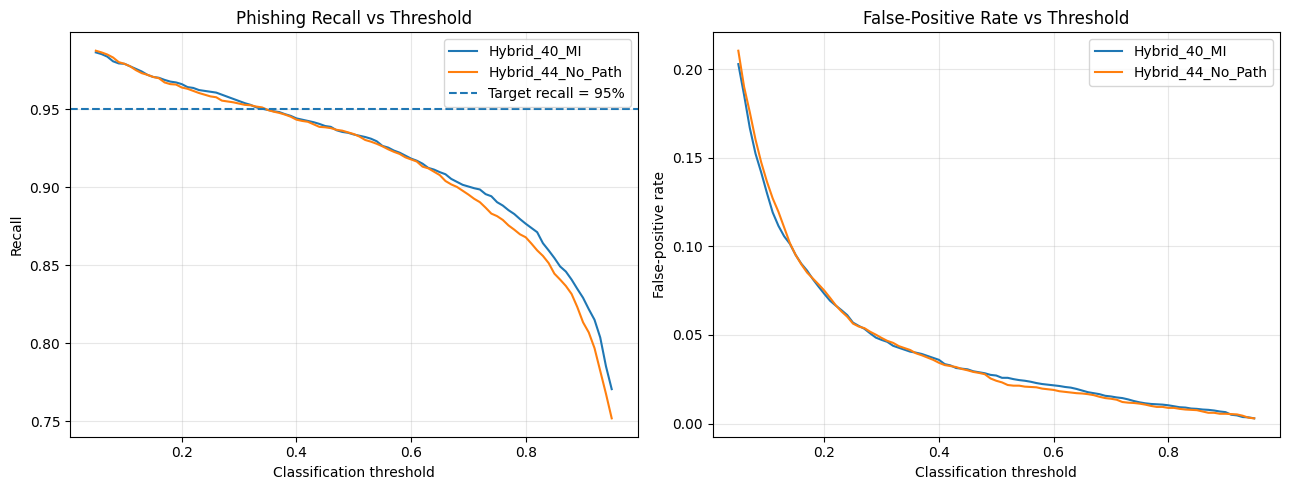

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in threshold_df.groupby("model"):

    group = group.sort_values("threshold")

    axes[0].plot(
        group["threshold"],
        group["recall"],
        label=name
    )

    axes[1].plot(
        group["threshold"],
        group["fpr"],
        label=name
    )

axes[0].axhline(
    0.95,
    linestyle="--",
    label="Target recall = 95%"
)

axes[0].set_title("Phishing Recall vs Threshold")
axes[0].set_xlabel("Classification threshold")
axes[0].set_ylabel("Recall")

axes[1].set_title("False-Positive Rate vs Threshold")
axes[1].set_xlabel("Classification threshold")
axes[1].set_ylabel("False-positive rate")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:

default_results = threshold_df[
    threshold_df["threshold"] == 0.50
].copy()

print("DEFAULT THRESHOLD (0.50)")
display(
    default_results[
        [
            "model",
            "threshold",
            "recall",
            "precision",
            "f1",
            "fpr",
            "false_negatives",
            "false_positives"
        ]
    ].round(4)
)

print("\nRECALL-OPTIMIZED THRESHOLDS")
if not best_thresholds.empty:
    display(
        best_thresholds[
            [
                "model",
                "threshold",
                "recall",
                "precision",
                "f1",
                "fpr",
                "false_negatives",
                "false_positives"
            ]
        ].round(4)
    )


DEFAULT THRESHOLD (0.50)


,model,threshold,recall,precision,f1,fpr,false_negatives,false_positives
45,Hybrid_44_No_Path,0.5,0.9341,0.9634,0.9485,0.0242,243,131
136,Hybrid_40_MI,0.5,0.9338,0.9591,0.9463,0.0271,244,147



RECALL-OPTIMIZED THRESHOLDS


,model,threshold,recall,precision,f1,fpr,false_negatives,false_positives
0,Hybrid_40_MI,0.34,0.9504,0.9394,0.9449,0.0417,183,226
1,Hybrid_44_No_Path,0.34,0.9512,0.9382,0.9446,0.0426,180,231


# Test evaluation

In [ ]:

from google.colab import drive
from pathlib import Path

import pandas as pd
import numpy as np

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(
    FEATURE_DIR / "train_hybrid_features.csv"
)

test_df = pd.read_csv(
    FEATURE_DIR / "test_hybrid_features.csv"
)

mi_ranking = pd.read_csv(
    MODEL_DIR / "hybrid_mi_ranking.csv"
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTrain labels:")
print(train_df["label"].value_counts())

print("\nTest labels:")
print(test_df["label"].value_counts())


Training shape: (50000, 53)
Testing shape: (15000, 53)

Train labels:
label
benign    27770
phish     22230
Name: count, dtype: int64

Test labels:
label
benign    8145
phish     6855
Name: count, dtype: int64


In [ ]:

# =====================================================
# CELL 2 — VERIFY DATA AND PREPARE FINAL FEATURE SETS
# =====================================================

exclude_cols = {
    "source_row", "split", "label", "target",
    "sha256", "html_sha256", "html_parse_failed",
    "url", "hostname", "date", "lang", "lang_score"
}

# Select numerical features only
all_features = [
    col for col in train_df.select_dtypes(include="number").columns
    if col not in exclude_cols
]

print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Number of hybrid features:", len(all_features))

# Validate expected record counts
assert len(train_df) == 50000
assert len(test_df) == 15000
assert len(all_features) == 47

# Check unique identifiers
assert train_df["source_row"].is_unique
assert test_df["source_row"].is_unique

# Check target labels
assert set(train_df["label"].unique()) == {"benign", "phish"}
assert set(test_df["label"].unique()) == {"benign", "phish"}

# Verify alignment against the original selected records
train_selected = pd.read_csv(
    FEATURE_DIR / "train_selected_records.csv"
)

test_selected = pd.read_csv(
    FEATURE_DIR / "test_selected_records.csv"
)

for name, feature_df, selected_df in [
    ("train", train_df, train_selected),
    ("test", test_df, test_selected)
]:
    actual = (
        feature_df[["source_row", "label"]]
        .sort_values("source_row")
        .reset_index(drop=True)
    )

    expected = (
        selected_df[["source_row", "label"]]
        .sort_values("source_row")
        .reset_index(drop=True)
    )

    assert actual.equals(expected), (
        f"{name} feature records or labels do not match "
        "the original selected records."
    )

    print(f"{name.upper()} alignment: OK")

# Candidate A — Top 40 MI features
features_40 = mi_ranking["feature"].head(40).tolist()

# Candidate B — 44 features, removing URL path group
remove_path = {
    "path_length",
    "slash_count",
    "path_depth"
}

features_44 = [
    feature for feature in all_features
    if feature not in remove_path
]

assert len(features_40) == 40
assert len(set(features_40)) == 40
assert len(features_44) == 44

for features in [features_40, features_44]:
    assert set(features).issubset(train_df.columns)
    assert set(features).issubset(test_df.columns)

# Final configurations chosen using validation only
final_configurations = {
    "Hybrid_40_MI": {
        "features": features_40,
        "threshold": 0.34
    },
    "Hybrid_44_No_Path": {
        "features": features_44,
        "threshold": 0.34
    }
}

# Binary classification labels
# 1 = phishing, 0 = benign
y_train = (train_df["label"] == "phish").astype(int)
y_test = (test_df["label"] == "phish").astype(int)

print("\nFinal configurations verified successfully!")
print("Hybrid_40_MI:", len(features_40), "features")
print("Hybrid_44_No_Path:", len(features_44), "features")


Training records: 50000
Testing records: 15000
Number of hybrid features: 47
TRAIN alignment: OK
TEST alignment: OK

Final configurations verified successfully!
Hybrid_40_MI: 40 features
Hybrid_44_No_Path: 44 features


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

import joblib

final_results = []
final_models = {}
test_predictions = {}

for model_name, config in final_configurations.items():

    features = config["features"]
    threshold = config["threshold"]

    print(f"\nTraining final model: {model_name}")

    X_train = train_df[features]
    X_test = test_df[features]

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=150,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        )
    )

    # Train on all 50,000 official-training records
    model.fit(X_train, y_train)

    # Evaluate only now on official-test records
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn)

    metrics = {
        "model": model_name,
        "features": len(features),
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "fpr": fpr,
        "roc_auc": roc_auc_score(y_test, probabilities),
        "average_precision": average_precision_score(
            y_test, probabilities
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    final_results.append(metrics)
    final_models[model_name] = model

    test_predictions[model_name] = pd.DataFrame({
        "source_row": test_df["source_row"],
        "actual": y_test,
        "predicted": predictions,
        "phishing_probability": probabilities
    })

    print(f"Accuracy: {metrics['accuracy']:.4f}")
    print(f"Recall: {metrics['recall']:.4f}")
    print(f"Precision: {metrics['precision']:.4f}")
    print(f"F1: {metrics['f1']:.4f}")
    print(f"FPR: {metrics['fpr']:.4f}")
    print(f"False negatives: {fn}")
    print(f"False positives: {fp}")

    joblib.dump(
        {
            "model": model,
            "feature_names": features,
            "threshold": threshold
        },
        MODEL_DIR / f"{model_name}_final.joblib"
    )

    test_predictions[model_name].to_csv(
        MODEL_DIR / f"{model_name}_test_predictions.csv",
        index=False
    )

final_results_df = pd.DataFrame(final_results)

print("\nFINAL TEST RESULTS")
display(final_results_df.round(4))

final_results_df.to_csv(
    MODEL_DIR / "final_test_results.csv",
    index=False
)



Training final model: Hybrid_40_MI
Accuracy: 0.9300
Recall: 0.9020
Precision: 0.9424
F1: 0.9217
FPR: 0.0464
False negatives: 672
False positives: 378

Training final model: Hybrid_44_No_Path
Accuracy: 0.9333
Recall: 0.9119
Precision: 0.9403
F1: 0.9259
FPR: 0.0487
False negatives: 604
False positives: 397

FINAL TEST RESULTS


,model,features,threshold,accuracy,balanced_accuracy,precision,recall,f1,fpr,roc_auc,average_precision,TN,FP,FN,TP
0,Hybrid_40_MI,40,0.34,0.9300,0.9278,0.9424,0.9020,0.9217,0.0464,0.9781,0.9783,7767,378,672,6183
1,Hybrid_44_No_Path,44,0.34,0.9333,0.9316,0.9403,0.9119,0.9259,0.0487,0.9817,0.9801,7748,397,604,6251


In [ ]:

import pandas as pd
from pathlib import Path

# Mount Google Drive if necessary
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"
MODEL_DIR = PROJECT_DIR / "models"

# Load hybrid feature datasets
train_df = pd.read_csv(
    FEATURE_DIR / "train_hybrid_features.csv"
)

test_df = pd.read_csv(
    FEATURE_DIR / "test_hybrid_features.csv"
)

# Restore original domain-grouped split
split_df = pd.read_csv(
    MODEL_DIR / "train_validation_split.csv"
)

train_ids = set(
    split_df.loc[
        split_df["partition"] == "train",
        "source_row"
    ]
)

val_ids = set(
    split_df.loc[
        split_df["partition"] == "validation",
        "source_row"
    ]
)

# Recreate training and validation DataFrames
dev_train = train_df[
    train_df["source_row"].isin(train_ids)
].copy()

validation = train_df[
    train_df["source_row"].isin(val_ids)
].copy()

# Verify the split
assert train_ids.isdisjoint(val_ids)
assert len(dev_train) + len(validation) == len(train_df)
assert dev_train["source_row"].is_unique
assert validation["source_row"].is_unique

print("Training records:", len(dev_train))
print("Validation records:", len(validation))
print("Testing records:", len(test_df))

print("\nData restored successfully!")


Training records: 40889
Validation records: 9111
Testing records: 15000

Data restored successfully!


In [ ]:

# Load MI feature rankings
mi_ranking = pd.read_csv(
    MODEL_DIR / "hybrid_mi_ranking.csv"
)

exclude_cols = {
    "source_row", "split", "label", "target",
    "sha256", "html_sha256", "html_parse_failed",
    "url", "hostname", "date", "lang", "lang_score"
}

all_features = [
    c for c in train_df.select_dtypes(include="number").columns
    if c not in exclude_cols
]

features_40 = mi_ranking["feature"].head(40).tolist()

features_44 = [
    c for c in all_features
    if c not in {"path_length", "slash_count", "path_depth"}
]

final_configurations = {
    "Hybrid_40_MI": {
        "features": features_40,
        "threshold": 0.34
    },
    "Hybrid_44_No_Path": {
        "features": features_44,
        "threshold": 0.34
    }
}

assert len(features_40) == 40
assert len(features_44) == 44

print("Final model configurations restored!")


Final model configurations restored!


In [ ]:

results = []
comparison_models = {}

for model_name, config in final_configurations.items():

    features = config["features"]
    threshold = config["threshold"]

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=150,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        )
    )

    y_dev = (dev_train["label"] == "phish").astype(int)

    model.fit(dev_train[features], y_dev)
    comparison_models[model_name] = model

    for split_name, df in [
        ("Train", dev_train),
        ("Validation", validation),
        ("Test", test_df)
    ]:
        y_true = (df["label"] == "phish").astype(int)

        probabilities = model.predict_proba(
            df[features]
        )[:, 1]

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            predictions,
            labels=[0, 1]
        ).ravel()

        results.append({
            "model": model_name,
            "split": split_name,
            "records": len(df),
            "accuracy": accuracy_score(y_true, predictions),
            "precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_true, predictions, zero_division=0
            ),
            "fpr": fp / (fp + tn) if fp + tn else 0,
            "false_negatives": int(fn),
            "false_positives": int(fp)
        })

comparison_df = pd.DataFrame(results)

print("TRAIN / VALIDATION / TEST COMPARISON")
display(comparison_df.round(4))

comparison_df.to_csv(
    MODEL_DIR / "train_val_test_comparison.csv",
    index=False
)


TRAIN / VALIDATION / TEST COMPARISON


,model,split,records,accuracy,precision,recall,f1,fpr,false_negatives,false_positives
0,Hybrid_40_MI,Train,40889,0.9817,0.9718,0.9884,0.9800,0.0238,216,532
1,Hybrid_40_MI,Validation,9111,0.9551,0.9394,0.9504,0.9449,0.0417,183,226
2,Hybrid_40_MI,Test,15000,0.9277,0.9443,0.8945,0.9187,0.0444,723,362
3,Hybrid_44_No_Path,Train,40889,0.9813,0.9713,0.9881,0.9796,0.0243,221,542
4,Hybrid_44_No_Path,Validation,9111,0.9549,0.9382,0.9512,0.9446,0.0426,180,231
5,Hybrid_44_No_Path,Test,15000,0.9408,0.9421,0.9275,0.9347,0.0480,497,391


# Full Data model

In [ ]:

%pip install -q datasets lxml pandas pyarrow

from google.colab import drive
from pathlib import Path

import pandas as pd
import numpy as np
import hashlib
import math
import re
import ipaddress
import shutil
import gc

from urllib.parse import urlsplit
from lxml import html as lxml_html
from datasets import load_dataset

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")
FEATURE_DIR = PROJECT_DIR / "features"

FULL_DIR = PROJECT_DIR / "full_dataset_features"
FULL_DIR.mkdir(parents=True, exist_ok=True)

REPO = "phreshphish/phreshphish"
BATCH_SIZE = 1000

EXPECTED_ROWS = {
    "train": 498255,
    "test": 168060
}

print("Full dataset output:", FULL_DIR)
print("Batch size:", BATCH_SIZE)


Mounted at /content/drive
Full dataset output: /content/drive/MyDrive/PhreshPhish_Project/full_dataset_features
Batch size: 1000


In [ ]:

def calculate_entropy(text):
    if not text:
        return 0.0

    probabilities = [
        text.count(ch) / len(text)
        for ch in set(text)
    ]

    return -sum(p * math.log2(p) for p in probabilities)


def is_ip_address(hostname):
    try:
        ipaddress.ip_address(hostname)
        return 1
    except ValueError:
        return 0


def extract_url_features(url):
    url = str(url or "").strip()

    clean = re.sub(
        r"^https?://", "", url, flags=re.IGNORECASE
    )

    try:
        parsed = urlsplit("http://" + clean)
        hostname = (parsed.hostname or "").lower()
        path = parsed.path or ""
        query = parsed.query or ""
        fragment = parsed.fragment or ""
    except ValueError:
        hostname = ""
        path = ""
        query = ""
        fragment = ""

    length = len(clean)
    digits = sum(ch.isdigit() for ch in clean)
    letters = sum(ch.isalpha() for ch in clean)
    special = sum(not ch.isalnum() for ch in clean)

    tokens = [
        t for t in re.split(r"[^A-Za-z0-9]+", clean) if t
    ]
    hostname_parts = [p for p in hostname.split(".") if p]

    features = {
        "url_length": length,
        "hostname_length": len(hostname),
        "path_length": len(path),
        "query_length": len(query),
        "fragment_length": len(fragment),
        "path_depth": len([p for p in path.split("/") if p]),
        "subdomain_count": max(0, len(hostname_parts) - 2),
        "digit_count": digits,
        "letter_count": letters,
        "special_char_count": special,
        "dot_count": clean.count("."),
        "hyphen_count": clean.count("-"),
        "underscore_count": clean.count("_"),
        "slash_count": clean.count("/"),
        "at_count": clean.count("@"),
        "percent_count": clean.count("%"),
        "question_count": clean.count("?"),
        "equals_count": clean.count("="),
        "ampersand_count": clean.count("&"),
        "digit_ratio": digits / max(length, 1),
        "special_char_ratio": special / max(length, 1),
        "url_entropy": calculate_entropy(clean),
        "token_count": len(tokens),
        "max_token_length": max(
            (len(t) for t in tokens), default=0
        ),
        "avg_token_length": (
            sum(len(t) for t in tokens) / len(tokens)
            if tokens else 0
        ),
        "hostname_is_ip": is_ip_address(hostname),
        "contains_punycode": int("xn--" in hostname),
        "has_query": int(bool(query))
    }

    assert len(features) == 28
    return features, hostname


In [ ]:

def extract_html_features(html_text):
    html_text = str(html_text or "")

    features = {
        "html_length": len(html_text),
        "html_tag_count": 0,
        "html_text_length": 0,
        "html_title_present": 0,
        "html_form_count": 0,
        "html_input_count": 0,
        "html_password_input_count": 0,
        "html_hidden_input_count": 0,
        "html_link_count": 0,
        "html_absolute_link_count": 0,
        "html_relative_link_count": 0,
        "html_empty_link_count": 0,
        "html_javascript_link_count": 0,
        "html_image_count": 0,
        "html_script_count": 0,
        "html_stylesheet_count": 0,
        "html_iframe_count": 0,
        "html_meta_refresh_count": 0,
        "html_button_count": 0
    }

    if not html_text.strip():
        return features, 1

    try:
        root = lxml_html.fromstring(html_text)
        features["html_text_length"] = len(root.text_content())

        for node in root.iter():
            if not isinstance(node.tag, str):
                continue

            tag = node.tag.lower()
            features["html_tag_count"] += 1

            if tag == "title":
                if (node.text_content() or "").strip():
                    features["html_title_present"] = 1

            elif tag == "form":
                features["html_form_count"] += 1

            elif tag == "input":
                features["html_input_count"] += 1
                input_type = (
                    node.get("type") or ""
                ).strip().lower()

                if input_type == "password":
                    features["html_password_input_count"] += 1
                if input_type == "hidden":
                    features["html_hidden_input_count"] += 1

            elif tag == "a":
                features["html_link_count"] += 1
                href = (node.get("href") or "").strip()
                href_lower = href.lower()

                if not href or href == "#":
                    features["html_empty_link_count"] += 1
                elif href_lower.startswith("javascript:"):
                    features["html_javascript_link_count"] += 1
                elif href_lower.startswith(
                    ("http://", "https://", "//")
                ):
                    features["html_absolute_link_count"] += 1
                else:
                    features["html_relative_link_count"] += 1

            elif tag == "img":
                features["html_image_count"] += 1
            elif tag == "script":
                features["html_script_count"] += 1
            elif tag == "link":
                rel = (node.get("rel") or "").strip().lower()
                if "stylesheet" in rel.split():
                    features["html_stylesheet_count"] += 1
            elif tag == "iframe":
                features["html_iframe_count"] += 1
            elif tag == "meta":
                equiv = (
                    node.get("http-equiv") or ""
                ).strip().lower()
                if equiv == "refresh":
                    features["html_meta_refresh_count"] += 1
            elif tag == "button":
                features["html_button_count"] += 1

        return features, 0

    except Exception:
        return features, 1


In [ ]:

reference_records = {}

for split in ["train", "test"]:
    path = FEATURE_DIR / f"{split}_selected_records.csv"

    reference = pd.read_csv(
        path,
        usecols=["source_row", "url", "label"]
    )

    reference_records[split] = reference.set_index(
        "source_row"
    )

    print(
        split,
        "reference records:",
        len(reference_records[split])
    )


train reference records: 50000
test reference records: 15000


In [ ]:

def save_full_batch(split, rows, start_row):
    folder = FULL_DIR / split
    folder.mkdir(parents=True, exist_ok=True)

    filename = f"batch_{start_row:09d}.csv.gz"

    local_path = Path("/content") / filename
    temp_path = folder / (filename + ".tmp")
    final_path = folder / filename

    batch = pd.DataFrame(rows)

    batch.to_csv(
        local_path,
        index=False,
        compression="gzip"
    )

    shutil.copy2(local_path, temp_path)
    temp_path.replace(final_path)
    local_path.unlink()

    return len(batch)


def run_full_feature_extraction(split):
    folder = FULL_DIR / split
    folder.mkdir(parents=True, exist_ok=True)

    expected = EXPECTED_ROWS[split]
    references = reference_records[split]

    # Find first batch that has not been saved.
    start_row = 0

    while True:
        batch_path = folder / f"batch_{start_row:09d}.csv.gz"

        if not batch_path.exists():
            break

        # Verify saved batch before trusting its checkpoint.
        saved = pd.read_csv(
            batch_path,
            usecols=["source_row"]
        )["source_row"]

        expected_size = min(
            BATCH_SIZE, expected - start_row
        )

        if (
            len(saved) != expected_size
            or saved.iloc[0] != start_row
            or saved.iloc[-1] != start_row + expected_size - 1
        ):
            raise ValueError(
                f"Invalid checkpoint: {batch_path}"
            )

        start_row += expected_size

        if start_row >= expected:
            break

    print(f"\n{split.upper()}")
    print("Expected records:", expected)
    print("Already extracted:", start_row)

    if start_row == expected:
        print("This split is already complete.")
        return

    stream = load_dataset(
        REPO,
        split=split,
        streaming=True
    )

    # Resume without reprocessing completed batches.
    # Remote reading/skipping may still incur network traffic.
    if start_row:
        stream = stream.skip(start_row)

    buffer = []
    batch_start = start_row
    processed = start_row

    for record in stream:
        if processed >= expected:
            raise ValueError("Unexpected extra records")

        url = str(record.get("url") or "")
        label = str(record.get("label") or "")
        html_text = str(record.get("html") or "")

        # Verify source ordering against the original sample.
        if processed in references.index:
            ref = references.loc[processed]

            if (
                url != str(ref["url"])
                or label != str(ref["label"])
            ):
                raise ValueError(
                    f"Dataset mismatch at row {processed}. "
                    "Stop: source order or version changed."
                )

        url_features, hostname = extract_url_features(url)

        html_features, parse_failed = extract_html_features(
            html_text
        )

        # Hash the original HTML for overlap auditing.
        html_hash = hashlib.sha256(
            html_text.encode("utf-8", errors="replace")
        ).hexdigest()

        output = {
            "source_row": processed,
            "label": label,
            "hostname": hostname,
            "html_sha256": html_hash,
            "html_parse_failed": parse_failed,
            **url_features,
            **html_features
        }

        buffer.append(output)
        processed += 1

        if len(buffer) >= BATCH_SIZE:
            save_full_batch(split, buffer, batch_start)

            batch_start = processed
            buffer.clear()

            print(
                f"{split}: {processed:,} / {expected:,}",
                flush=True
            )

            gc.collect()

    if buffer:
        save_full_batch(split, buffer, batch_start)
        buffer.clear()

    if processed != expected:
        raise ValueError(
            f"Incomplete extraction: {processed} / {expected}"
        )

    print(f"\n{split} extraction finished successfully.")


In [ ]:

run_full_feature_extraction("train")



TRAIN
Expected records: 498255
Already extracted: 0


README.md:   0%|          | 0.00/4.28k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

train: 1,000 / 498,255
train: 2,000 / 498,255
train: 3,000 / 498,255
train: 4,000 / 498,255
train: 5,000 / 498,255
train: 6,000 / 498,255
train: 7,000 / 498,255
train: 8,000 / 498,255
train: 9,000 / 498,255
train: 10,000 / 498,255
train: 11,000 / 498,255
train: 12,000 / 498,255
train: 13,000 / 498,255
train: 14,000 / 498,255
train: 15,000 / 498,255
train: 16,000 / 498,255
train: 17,000 / 498,255
train: 18,000 / 498,255
train: 19,000 / 498,255
train: 20,000 / 498,255
train: 21,000 / 498,255
train: 22,000 / 498,255
train: 23,000 / 498,255
train: 24,000 / 498,255
train: 25,000 / 498,255
train: 26,000 / 498,255
train: 27,000 / 498,255
train: 28,000 / 498,255
train: 29,000 / 498,255
train: 30,000 / 498,255
train: 31,000 / 498,255
train: 32,000 / 498,255
train: 33,000 / 498,255
train: 34,000 / 498,255
train: 35,000 / 498,255
train: 36,000 / 498,255
train: 37,000 / 498,255
train: 38,000 / 498,255
train: 39,000 / 498,255
train: 40,000 / 498,255
train: 41,000 / 498,255
train: 42,000 / 498,255
t

In [ ]:

run_full_feature_extraction("test")



TEST
Expected records: 168060
Already extracted: 0


Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/56 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/21 [00:00<?, ?it/s]

test: 1,000 / 168,060
test: 2,000 / 168,060
test: 3,000 / 168,060
test: 4,000 / 168,060
test: 5,000 / 168,060
test: 6,000 / 168,060
test: 7,000 / 168,060
test: 8,000 / 168,060
test: 9,000 / 168,060
test: 10,000 / 168,060
test: 11,000 / 168,060
test: 12,000 / 168,060
test: 13,000 / 168,060
test: 14,000 / 168,060
test: 15,000 / 168,060
test: 16,000 / 168,060
test: 17,000 / 168,060
test: 18,000 / 168,060
test: 19,000 / 168,060
test: 20,000 / 168,060
test: 21,000 / 168,060
test: 22,000 / 168,060
test: 23,000 / 168,060
test: 24,000 / 168,060
test: 25,000 / 168,060
test: 26,000 / 168,060
test: 27,000 / 168,060
test: 28,000 / 168,060
test: 29,000 / 168,060
test: 30,000 / 168,060
test: 31,000 / 168,060
test: 32,000 / 168,060
test: 33,000 / 168,060
test: 34,000 / 168,060
test: 35,000 / 168,060
test: 36,000 / 168,060
test: 37,000 / 168,060
test: 38,000 / 168,060
test: 39,000 / 168,060
test: 40,000 / 168,060
test: 41,000 / 168,060
test: 42,000 / 168,060
test: 43,000 / 168,060
test: 44,000 / 168,0

In [ ]:

import pyarrow as pa
import pyarrow.parquet as pq

def consolidate_full_features(split):
    folder = FULL_DIR / split
    files = sorted(folder.glob("batch_*.csv.gz"))

    if not files:
        raise FileNotFoundError(
            f"No extracted batches found for {split}"
        )

    expected = EXPECTED_ROWS[split]
    output_path = FULL_DIR / f"{split}_full_features.parquet"

    local_output = Path("/content") / output_path.name
    writer = None
    total_rows = 0

    try:
        for file in files:
            batch = pd.read_csv(file)

            # All 47 predictors should be numerical.
            table = pa.Table.from_pandas(
                batch,
                preserve_index=False
            )

            if writer is None:
                writer = pq.ParquetWriter(
                    str(local_output),
                    table.schema,
                    compression="snappy"
                )

            writer.write_table(table)
            total_rows += len(batch)

        if total_rows != expected:
            raise ValueError(
                f"{split}: expected {expected}, "
                f"found {total_rows}. File not published."
            )

    finally:
        if writer is not None:
            writer.close()

    shutil.copy2(local_output, output_path)
    local_output.unlink()

    print(split, "rows:", total_rows)
    print("Saved:", output_path)


consolidate_full_features("train")
consolidate_full_features("test")


train rows: 498255
Saved: /content/drive/MyDrive/PhreshPhish_Project/full_dataset_features/train_full_features.parquet
test rows: 168060
Saved: /content/drive/MyDrive/PhreshPhish_Project/full_dataset_features/test_full_features.parquet


In [ ]:

metadata_cols = {
    "source_row",
    "label",
    "hostname",
    "html_sha256",
    "html_parse_failed"
}

for split in ["train", "test"]:
    df = pd.read_parquet(
        FULL_DIR / f"{split}_full_features.parquet"
    )

    numeric_features = [
        c for c in df.columns
        if c not in metadata_cols
    ]

    print(f"\n{'=' * 45}")
    print(split.upper())
    print("=" * 45)

    print("Records:", len(df))
    print("Numerical features:", len(numeric_features))
    print("Missing feature values:",
          df[numeric_features].isna().sum().sum())
    print("HTML parsing failures:",
          df["html_parse_failed"].sum())
    print("Duplicate source rows:",
          df["source_row"].duplicated().sum())

    print("\nClass distribution:")
    print(df["label"].value_counts())

    assert len(df) == EXPECTED_ROWS[split]
    assert len(numeric_features) == 47
    assert df["source_row"].is_unique
    assert not df[numeric_features].isna().any().any()

print("\nFull dataset feature extraction verified.")



TRAIN
Records: 498255
Numerical features: 47
Missing feature values: 0
HTML parsing failures: 4
Duplicate source rows: 0

Class distribution:
label
benign    276729
phish     221526
Name: count, dtype: int64

TEST
Records: 168060
Numerical features: 47
Missing feature values: 0
HTML parsing failures: 0
Duplicate source rows: 0

Class distribution:
label
benign    91260
phish     76800
Name: count, dtype: int64

Full dataset feature extraction verified.


In [ ]:

import pandas as pd
from pathlib import Path

FULL_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/full_dataset_features"
)

train_full = pd.read_parquet(
    FULL_DIR / "train_full_features.parquet"
)

print("Training shape:", train_full.shape)
print("\nClass distribution:")
print(train_full["label"].value_counts())

print("\nFirst five records:")
display(train_full.head())


Training shape: (498255, 52)

Class distribution:
label
benign    276729
phish     221526
Name: count, dtype: int64

First five records:


,source_row,label,hostname,html_sha256,html_parse_failed,url_length,hostname_length,path_length,query_length,fragment_length,...,html_absolute_link_count,html_relative_link_count,html_empty_link_count,html_javascript_link_count,html_image_count,html_script_count,html_stylesheet_count,html_iframe_count,html_meta_refresh_count,html_button_count
0,0,benign,www.lifeonthemediterranean.com,c361661da533effdaac55163d61b7eec1accc840afdd08...,0,61,30,31,0,0,...,128,22,9,0,93,38,1,12,0,5
1,1,benign,moneypuck.com,d5d7cb9bee19e1c377ab016d028d7bde0a3b80bfbf85f9...,0,25,13,12,0,0,...,0,28,0,0,91,26,4,8,0,0
2,2,benign,learn.microsoft.com,875c5f5ded0d33fe0aab393f922ab48aa6119f05297c46...,0,81,19,62,0,0,...,61,174,4,0,22,7,1,0,0,56
3,3,benign,www.grandcanyondestinations.com,68b4c3fa3839a9db7fd5f134115aefcb1edbd562e6452b...,0,58,31,27,0,0,...,71,4,4,0,18,39,6,2,0,1
4,4,benign,pgcps-md.safeschools.com,cfa9639309c5617b31888b47a24e87b2f989c0d77e3d27...,0,89,24,65,0,0,...,10,1,0,0,5,23,4,2,0,4


In [ ]:

%pip install -q tldextract

import pandas as pd
import numpy as np
import tldextract

from sklearn.model_selection import GroupShuffleSplit
from pathlib import Path

FULL_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/full_dataset_features"
)

extractor = tldextract.TLDExtract(suffix_list_urls=None)

def registered_domain(host):
    host = str(host or "").strip().lower()

    if not host or host == "nan":
        return ""

    result = extractor(host)
    return result.top_domain_under_public_suffix or host

# Restore an existing split if previously saved
split_path = FULL_DIR / "full_train_validation_split.csv"

if split_path.exists():
    split_df = pd.read_csv(split_path)
    print("Loaded existing split.")

else:
    split_df = train_full[
        ["source_row", "label", "hostname"]
    ].copy()

    split_df["domain_group"] = (
        split_df["hostname"].map(registered_domain)
    )

    missing = split_df["domain_group"].eq("")

    split_df.loc[missing, "domain_group"] = (
        "missing_"
        + split_df.loc[missing, "source_row"].astype(str)
    )

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=42
    )

    train_idx, val_idx = next(
        splitter.split(
            split_df,
            y=split_df["label"],
            groups=split_df["domain_group"]
        )
    )

    split_df["partition"] = "train"
    split_df.iloc[
        val_idx,
        split_df.columns.get_loc("partition")
    ] = "validation"

    split_df.to_csv(split_path, index=False)
    print("Created and saved new split.")

# Verify record identity and grouping
assert split_df["source_row"].is_unique
assert set(split_df["source_row"]) == set(train_full["source_row"])

train_groups = set(
    split_df.loc[
        split_df["partition"] == "train", "domain_group"
    ]
)

val_groups = set(
    split_df.loc[
        split_df["partition"] == "validation", "domain_group"
    ]
)

assert train_groups.isdisjoint(val_groups)

print("\nPartition sizes:")
print(split_df["partition"].value_counts())

print("\nClass distribution (%):")
display(
    pd.crosstab(
        split_df["partition"],
        split_df["label"],
        normalize="index"
    ).mul(100).round(2)
)

print("\nShared registered domains:", len(train_groups & val_groups))
print("Split saved to:", split_path)


Created and saved new split.

Partition sizes:
partition
train         384095
validation    114160
Name: count, dtype: int64

Class distribution (%):


label,benign,phish
partition,,
train,58.82,41.18
validation,44.49,55.51



Shared registered domains: 0
Split saved to: /content/drive/MyDrive/PhreshPhish_Project/full_dataset_features/full_train_validation_split.csv


In [ ]:

import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# Use domain groups already calculated
df = split_df.copy()

target_phish_rate = (
    df["label"].eq("phish").mean()
)

target_val_fraction = 0.20

best_score = float("inf")
best_train_idx = None
best_val_idx = None

splitter = GroupShuffleSplit(
    n_splits=100,
    test_size=0.20,
    random_state=42
)

for train_idx, val_idx in splitter.split(
    df,
    groups=df["domain_group"]
):
    train_phish_rate = (
        df.iloc[train_idx]["label"].eq("phish").mean()
    )

    val_phish_rate = (
        df.iloc[val_idx]["label"].eq("phish").mean()
    )

    val_fraction = len(val_idx) / len(df)

    score = (
        abs(train_phish_rate - target_phish_rate)
        + abs(val_phish_rate - target_phish_rate)
        + abs(val_fraction - target_val_fraction)
    )

    if score < best_score:
        best_score = score
        best_train_idx = train_idx
        best_val_idx = val_idx

# Assign selected partition
df["partition"] = "train"
df.iloc[
    best_val_idx,
    df.columns.get_loc("partition")
] = "validation"

# Verify domain separation
train_groups = set(
    df.loc[df["partition"] == "train", "domain_group"]
)

val_groups = set(
    df.loc[df["partition"] == "validation", "domain_group"]
)

assert train_groups.isdisjoint(val_groups)

# Save the improved split
split_df = df.copy()

split_df.to_csv(
    FULL_DIR / "full_train_validation_split.csv",
    index=False
)

print("Improved split saved.")

print("\nPartition sizes:")
print(split_df["partition"].value_counts())

print("\nClass distribution (%):")
display(
    pd.crosstab(
        split_df["partition"],
        split_df["label"],
        normalize="index"
    ).mul(100).round(2)
)

print("\nShared registered domains:", len(train_groups & val_groups))


Improved split saved.

Partition sizes:
partition
train         398231
validation    100024
Name: count, dtype: int64

Class distribution (%):


label,benign,phish
partition,,
train,55.63,44.37
validation,55.19,44.81



Shared registered domains: 0


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

FULL_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/full_dataset_features"
)

train_full = pd.read_parquet(
    FULL_DIR / "train_full_features.parquet"
)

split_df = pd.read_csv(
    FULL_DIR / "full_train_validation_split.csv"
)

# Join partition labels using source_row, not row position
df = train_full.merge(
    split_df[["source_row", "partition", "domain_group"]],
    on="source_row",
    how="inner",
    validate="one_to_one"
)

assert len(df) == len(train_full)
assert set(df["partition"]) == {"train", "validation"}

train_data = df[df["partition"] == "train"].copy()
val_data = df[df["partition"] == "validation"].copy()

assert set(train_data["domain_group"]).isdisjoint(
    set(val_data["domain_group"])
)

print("Training records:", len(train_data))
print("Validation records:", len(val_data))

print("\nClass distribution (%):")
display(
    pd.crosstab(
        df["partition"],
        df["label"],
        normalize="index"
    ).mul(100).round(2)
)


Training records: 398231
Validation records: 100024

Class distribution (%):


label,benign,phish
partition,,
train,55.63,44.37
validation,55.19,44.81


In [ ]:

exclude_cols = {
    "source_row",
    "label",
    "hostname",
    "html_sha256",
    "html_parse_failed",
    "partition",
    "domain_group"
}

feature_cols = [
    col for col in train_data.select_dtypes(
        include="number"
    ).columns
    if col not in exclude_cols
]

assert len(feature_cols) == 47, (
    f"Expected 47 features, found {len(feature_cols)}"
)

X_val = val_data[feature_cols]
y_val = (val_data["label"] == "phish").astype(int)

print("Number of features:", len(feature_cols))
print("Validation shape:", X_val.shape)


Number of features: 47
Validation shape: (100024, 47)


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# Shuffle training rows reproducibly
ordered_train = train_data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

requested_sizes = [40000, 100000, 200000, 300000]

# Always include the complete available training partition
sizes = sorted(set(
    [n for n in requested_sizes if n < len(ordered_train)]
    + [len(ordered_train)]
))

results = []

for n in sizes:

    subset = ordered_train.iloc[:n]

    X_train = subset[feature_cols]
    y_train = (subset["label"] == "phish").astype(int)

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=150,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        )
    )

    print(f"\nTraining on {n:,} records...", flush=True)

    model.fit(X_train, y_train)

    for split_name, X, y in [
        ("Train", X_train, y_train),
        ("Validation", X_val, y_val)
    ]:

        pred = model.predict(X)

        tn, fp, fn, tp = confusion_matrix(
            y, pred, labels=[0, 1]
        ).ravel()

        results.append({
            "training_size": n,
            "split": split_name,
            "accuracy": accuracy_score(y, pred),
            "precision": precision_score(
                y, pred, zero_division=0
            ),
            "recall": recall_score(
                y, pred, zero_division=0
            ),
            "f1": f1_score(y, pred, zero_division=0),
            "fpr": fp / (fp + tn),
            "false_negatives": int(fn),
            "false_positives": int(fp)
        })

    # Save after each training size in case Colab disconnects
    learning_df = pd.DataFrame(results)

    learning_df.to_csv(
        FULL_DIR / "learning_curve_results.csv",
        index=False
    )

    latest = learning_df[
        (learning_df["training_size"] == n) &
        (learning_df["split"] == "Validation")
    ].iloc[0]

    print(
        f"Validation accuracy: {latest['accuracy']:.4f} | "
        f"Recall: {latest['recall']:.4f} | "
        f"F1: {latest['f1']:.4f} | "
        f"FPR: {latest['fpr']:.4f}",
        flush=True
    )

display(learning_df.round(4))



Training on 40,000 records...
Validation accuracy: 0.9354 | Recall: 0.8852 | F1: 0.9247 | FPR: 0.0238

Training on 100,000 records...
Validation accuracy: 0.9285 | Recall: 0.8766 | F1: 0.9166 | FPR: 0.0294

Training on 200,000 records...
Validation accuracy: 0.9256 | Recall: 0.8624 | F1: 0.9122 | FPR: 0.0231

Training on 300,000 records...
Validation accuracy: 0.9287 | Recall: 0.8682 | F1: 0.9160 | FPR: 0.0222

Training on 398,231 records...
Validation accuracy: 0.9273 | Recall: 0.8651 | F1: 0.9143 | FPR: 0.0222


,training_size,split,accuracy,precision,recall,f1,fpr,false_negatives,false_positives
0,40000,Train,0.9833,0.9855,0.9768,0.9811,0.0115,413,255
1,40000,Validation,0.9354,0.9679,0.8852,0.9247,0.0238,5144,1314
2,100000,Train,0.9777,0.9803,0.9694,0.9748,0.0157,1364,870
3,100000,Validation,0.9285,0.9604,0.8766,0.9166,0.0294,5532,1621
4,200000,Train,0.9755,0.9781,0.9663,0.9722,0.0173,2985,1920
5,200000,Validation,0.9256,0.9681,0.8624,0.9122,0.0231,6165,1274
6,300000,Train,0.9754,0.9776,0.9667,0.9721,0.0177,4440,2950
7,300000,Validation,0.9287,0.9694,0.8682,0.9160,0.0222,5908,1228
8,398231,Train,0.9747,0.9766,0.9662,0.9713,0.0185,5981,4094
9,398231,Validation,0.9273,0.9693,0.8651,0.9143,0.0222,6044,1227


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

X_train = train_data[feature_cols]
y_train = (train_data["label"] == "phish").astype(int)

X_val = val_data[feature_cols]
y_val = (val_data["label"] == "phish").astype(int)

full_model = make_pipeline(
    SimpleImputer(strategy="median"),
    HistGradientBoostingClassifier(
        max_iter=150,
        max_leaf_nodes=31,
        learning_rate=0.1,
        random_state=42
    )
)

full_model.fit(X_train, y_train)

val_prob = full_model.predict_proba(X_val)[:, 1]

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, val_prob), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, val_prob), 4))


PR-AUC (Average Precision): 0.9861
ROC-AUC: 0.9881


In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Test thresholds from 0.05 to 0.95
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)

results = []

for threshold in thresholds:

    predictions = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "fpr": fp / (fp + tn),
        "false_negatives": int(fn),
        "false_positives": int(fp)
    })

threshold_df = pd.DataFrame(results)

# Display commonly used thresholds
print("THRESHOLD COMPARISON")

display(
    threshold_df[
        threshold_df["threshold"].isin(
            [0.20, 0.25, 0.30, 0.34, 0.40, 0.50, 0.60]
        )
    ].round(4)
)

# Select lowest FPR with recall >= 95%
TARGET_RECALL = 0.95

eligible = threshold_df[
    threshold_df["recall"] >= TARGET_RECALL
]

if not eligible.empty:

    best_threshold = eligible.sort_values(
        ["fpr", "f1"],
        ascending=[True, False]
    ).iloc[0]

    print("\nBEST THRESHOLD FOR >= 95% RECALL")

    display(
        pd.DataFrame([best_threshold]).round(4)
    )

else:
    print("\nNo threshold achieved 95% recall.")

# Save the results to Google Drive
from pathlib import Path

FULL_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/full_dataset_features"
)

threshold_df.to_csv(
    FULL_DIR / "full_data_threshold_comparison.csv",
    index=False
)

print("\nResults saved successfully.")


THRESHOLD COMPARISON


,threshold,accuracy,precision,recall,f1,fpr,false_negatives,false_positives
15,0.20,0.9450,0.9163,0.9656,0.9403,0.0716,1543,3955
20,0.25,0.9458,0.9282,0.9528,0.9404,0.0598,2114,3303
25,0.30,0.9452,0.9398,0.9377,0.9388,0.0487,2791,2690
29,0.34,0.9433,0.9473,0.9250,0.9360,0.0418,3362,2306
35,0.40,0.9368,0.9545,0.9019,0.9274,0.0349,4396,1928
45,0.50,0.9267,0.9674,0.8656,0.9136,0.0237,6025,1309
55,0.60,0.9162,0.9756,0.8339,0.8992,0.0170,7443,936



BEST THRESHOLD FOR >= 95% RECALL


,threshold,accuracy,precision,recall,f1,fpr,false_negatives,false_positives
21,0.26,0.946,0.9305,0.9504,0.9403,0.0576,2222.0,3182.0



Results saved successfully.


# Final


In [ ]:

from google.colab import drive
from pathlib import Path

import pandas as pd
import numpy as np

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/PhreshPhish_Project")

FULL_DIR = PROJECT_DIR / "full_dataset_features"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_full = pd.read_parquet(
    FULL_DIR / "train_full_features.parquet"
)

test_full = pd.read_parquet(
    FULL_DIR / "test_full_features.parquet"
)

print("Training dataset:", train_full.shape)
print("Testing dataset:", test_full.shape)

print("\nTraining classes:")
print(train_full["label"].value_counts())

print("\nTesting classes:")
print(test_full["label"].value_counts())


Mounted at /content/drive
Training dataset: (498255, 52)
Testing dataset: (168060, 52)

Training classes:
label
benign    276729
phish     221526
Name: count, dtype: int64

Testing classes:
label
benign    91260
phish     76800
Name: count, dtype: int64


In [ ]:

exclude_cols = {
    "source_row",
    "label",
    "hostname",
    "html_sha256",
    "html_parse_failed"
}

feature_cols = [
    col for col in train_full.select_dtypes(
        include="number"
    ).columns
    if col not in exclude_cols
]

assert len(train_full) == 498255
assert len(test_full) == 168060

assert train_full["source_row"].is_unique
assert test_full["source_row"].is_unique

assert set(train_full["label"].unique()) == {
    "benign", "phish"
}

assert set(test_full["label"].unique()) == {
    "benign", "phish"
}

assert len(feature_cols) == 47, (
    f"Expected 47 numerical features, found {len(feature_cols)}"
)

assert set(feature_cols).issubset(test_full.columns)

X_train = train_full[feature_cols]
X_test = test_full[feature_cols]

y_train = (train_full["label"] == "phish").astype(int)
y_test = (test_full["label"] == "phish").astype(int)

FINAL_THRESHOLD = 0.26

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Feature count:", len(feature_cols))
print("Classification threshold:", FINAL_THRESHOLD)


Training shape: (498255, 47)
Testing shape: (168060, 47)
Feature count: 47
Classification threshold: 0.26


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

import joblib

final_model = make_pipeline(
    SimpleImputer(strategy="median"),
    HistGradientBoostingClassifier(
        max_iter=150,
        max_leaf_nodes=31,
        learning_rate=0.1,
        random_state=42
    )
)

print("Training final Gradient Boosting model...")

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

# Save the fitted model and its feature configuration
model_path = MODEL_DIR / "full_hybrid_gradient_boosting_final.joblib"

joblib.dump(
    {
        "model": final_model,
        "feature_names": feature_cols,
        "threshold": FINAL_THRESHOLD,
        "positive_class": "phish"
    },
    model_path
)

print("Model saved:", model_path)


Training final Gradient Boosting model...
Final model trained successfully!
Model saved: /content/drive/MyDrive/PhreshPhish_Project/models/full_hybrid_gradient_boosting_final.joblib


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Predict phishing probabilities
test_probabilities = final_model.predict_proba(
    X_test
)[:, 1]

# Apply the FIXED threshold chosen on validation
test_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

final_metrics = {
    "training_records": len(X_train),
    "testing_records": len(X_test),
    "num_features": len(feature_cols),
    "threshold": FINAL_THRESHOLD,
    "accuracy": accuracy_score(y_test, test_predictions),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, test_predictions
    ),
    "precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "f1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "fpr": fp / (fp + tn),
    "roc_auc": roc_auc_score(y_test, test_probabilities),
    "average_precision": average_precision_score(
        y_test, test_probabilities
    ),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp)
}

print("FINAL FULL-DATASET TEST RESULTS")
print("=" * 45)

for metric, value in final_metrics.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Benign", "Phishing"],
        digits=4
    )
)

final_results_df = pd.DataFrame([final_metrics])

display(final_results_df.T)

final_results_df.to_csv(
    MODEL_DIR / "full_dataset_final_test_results.csv",
    index=False
)

prediction_df = pd.DataFrame({
    "source_row": test_full["source_row"].values,
    "actual_label": y_test.values,
    "predicted_label": test_predictions,
    "phishing_probability": test_probabilities
})

prediction_df.to_csv(
    MODEL_DIR / "full_dataset_test_predictions.csv",
    index=False
)

print("\nFinal results and predictions saved.")


FINAL FULL-DATASET TEST RESULTS
training_records: 498255
testing_records: 168060
num_features: 47
threshold: 0.2600
accuracy: 0.9392
balanced_accuracy: 0.9385
precision: 0.9353
recall: 0.9312
f1: 0.9333
fpr: 0.0542
roc_auc: 0.9837
average_precision: 0.9842
true_negatives: 86315
false_positives: 4945
false_negatives: 5281
true_positives: 71519

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     0.9423    0.9458    0.9441     91260
    Phishing     0.9353    0.9312    0.9333     76800

    accuracy                         0.9392    168060
   macro avg     0.9388    0.9385    0.9387    168060
weighted avg     0.9391    0.9392    0.9391    168060



,0
training_records,498255.000000
testing_records,168060.000000
num_features,47.000000
threshold,0.260000
accuracy,0.939153
balanced_accuracy,0.938526
precision,0.935329
recall,0.931237
f1,0.933279
fpr,0.054186



Final results and predictions saved.


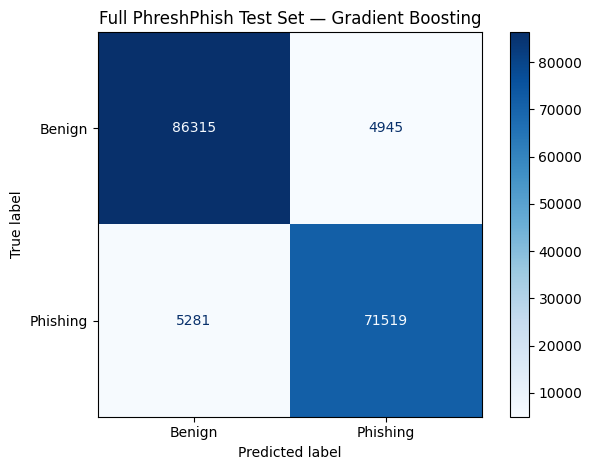

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Phishing"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Full PhreshPhish Test Set — Gradient Boosting"
)

plt.tight_layout()
plt.show()


In [ ]:

validation_metrics = {
    "accuracy": 0.9460,
    "precision": 0.9305,
    "recall": 0.9504,
    "f1": 0.9403,
    "fpr": 0.0576
}

comparison_rows = []

for metric, val_score in validation_metrics.items():
    test_score = final_metrics[metric]

    comparison_rows.append({
        "metric": metric,
        "validation": val_score,
        "test": test_score,
        "change_pp": (test_score - val_score) * 100
    })

comparison_df = pd.DataFrame(comparison_rows)

print("VALIDATION VS TEST COMPARISON")
display(comparison_df.round(4))

comparison_df.to_csv(
    MODEL_DIR / "full_validation_vs_test_comparison.csv",
    index=False
)


VALIDATION VS TEST COMPARISON


,metric,validation,test,change_pp
0,accuracy,0.9460,0.9392,-0.6847
1,precision,0.9305,0.9353,0.4829
2,recall,0.9504,0.9312,-1.9163
3,f1,0.9403,0.9333,-0.7021
4,fpr,0.0576,0.0542,-0.3414


# model on random forest

In [ ]:

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

FULL_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/full_dataset_features"
)

MODEL_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project/models"
)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_full = pd.read_parquet(
    FULL_DIR / "train_full_features.parquet"
)

split_df = pd.read_csv(
    FULL_DIR / "full_train_validation_split.csv"
)

df = train_full.merge(
    split_df[["source_row", "partition"]],
    on="source_row",
    how="inner",
    validate="one_to_one"
)

assert len(df) == len(train_full)

train_data = df[df["partition"] == "train"].copy()
val_data = df[df["partition"] == "validation"].copy()

exclude_cols = {
    "source_row",
    "label",
    "hostname",
    "html_sha256",
    "html_parse_failed",
    "partition"
}

feature_cols = [
    c for c in train_data.select_dtypes(include="number").columns
    if c not in exclude_cols
]

assert len(feature_cols) == 47

X_train = train_data[feature_cols]
X_val = val_data[feature_cols]

y_train = (train_data["label"] == "phish").astype(int)
y_val = (val_data["label"] == "phish").astype(int)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)


Training: (398231, 47)
Validation: (100024, 47)


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix,
    roc_auc_score, average_precision_score
)

rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=5,
        max_features="sqrt",
        n_jobs=2,
        random_state=42
    )
)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:",
      round(roc_auc_score(y_val, rf_val_prob), 4))
print("Validation average precision:",
      round(average_precision_score(y_val, rf_val_prob), 4))


Training Random Forest...
Validation ROC-AUC: 0.9884
Validation average precision: 0.9867


In [ ]:

rows = []

for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2):
    pred = (rf_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "fpr": fp / (fp + tn),
        "false_negatives": int(fn),
        "false_positives": int(fp)
    })

rf_threshold_df = pd.DataFrame(rows)

eligible = rf_threshold_df[
    rf_threshold_df["recall"] >= 0.95
]

if eligible.empty:
    print("No threshold achieved 95% validation recall.")
    rf_best = None
else:
    rf_best = eligible.sort_values(
        ["fpr", "f1"],
        ascending=[True, False]
    ).iloc[0]

    print("BEST RANDOM FOREST THRESHOLD")
    display(pd.DataFrame([rf_best]).round(4))

rf_threshold_df.to_csv(
    MODEL_DIR / "full_random_forest_threshold_results.csv",
    index=False
)


BEST RANDOM FOREST THRESHOLD


,threshold,accuracy,precision,recall,f1,fpr,false_negatives,false_positives
27,0.32,0.9512,0.9395,0.9523,0.9459,0.0498,2137.0,2747.0


RANDOM FOREST — VALIDATION CONFUSION MATRIX
Threshold: 0.32
True Negatives: 52461
False Positives: 2747
False Negatives: 2137
True Positives: 42679


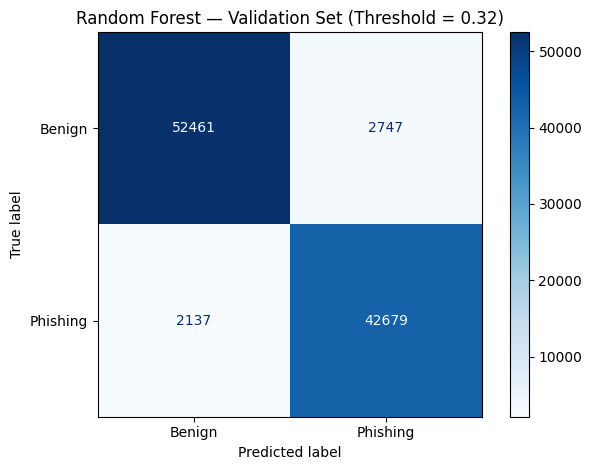


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     0.9609    0.9502    0.9555     55208
    Phishing     0.9395    0.9523    0.9459     44816

    accuracy                         0.9512    100024
   macro avg     0.9502    0.9513    0.9507    100024
weighted avg     0.9513    0.9512    0.9512    100024



<Figure size 640x480 with 0 Axes>

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Use the threshold selected from validation
if rf_best is None:
    raise ValueError(
        "No threshold achieved 95% recall. "
        "Choose a threshold using validation results first."
    )

rf_threshold = float(rf_best["threshold"])

# Predictions on VALIDATION data
rf_val_pred = (rf_val_prob >= rf_threshold).astype(int)

cm = confusion_matrix(
    y_val,
    rf_val_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("RANDOM FOREST — VALIDATION CONFUSION MATRIX")
print("Threshold:", rf_threshold)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Phishing"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(
    f"Random Forest — Validation Set (Threshold = {rf_threshold:.2f})"
)
plt.tight_layout()
plt.show()

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_val,
        rf_val_pred,
        target_names=["Benign", "Phishing"],
        digits=4
    )
)

# Save the confusion matrix
plt.savefig(
    MODEL_DIR / "random_forest_validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)


In [ ]:

exclude_cols = {
    "source_row",
    "label",
    "hostname",
    "html_sha256",
    "html_parse_failed"
}

feature_cols = [
    col for col in train_full.select_dtypes(
        include="number"
    ).columns
    if col not in exclude_cols
]

assert len(train_full) == 498255
assert len(test_full) == 168060
assert len(feature_cols) == 47
assert set(feature_cols).issubset(test_full.columns)

assert train_full["source_row"].is_unique
assert test_full["source_row"].is_unique

X_train = train_full[feature_cols]
X_test = test_full[feature_cols]

y_train = (train_full["label"] == "phish").astype(int)
y_test = (test_full["label"] == "phish").astype(int)

RF_THRESHOLD = 0.32

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Threshold:", RF_THRESHOLD)


Training shape: (498255, 47)
Testing shape: (168060, 47)
Threshold: 0.32


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
import joblib

rf_final_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=5,
        max_features="sqrt",
        n_jobs=2,
        random_state=42
    )
)

print("Training full-data Random Forest...")

rf_final_model.fit(X_train, y_train)

print("Random Forest training completed!")

joblib.dump(
    {
        "model": rf_final_model,
        "feature_names": feature_cols,
        "threshold": RF_THRESHOLD,
        "positive_class": "phish"
    },
    MODEL_DIR / "full_random_forest_final.joblib"
)

print("Model saved to Google Drive.")


Training full-data Random Forest...
Random Forest training completed!
Model saved to Google Drive.


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

rf_test_prob = rf_final_model.predict_proba(X_test)[:, 1]

rf_test_pred = (
    rf_test_prob >= RF_THRESHOLD
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    rf_test_pred,
    labels=[0, 1]
).ravel()

rf_final_metrics = {
    "model": "Random Forest",
    "training_records": len(X_train),
    "testing_records": len(X_test),
    "num_features": len(feature_cols),
    "threshold": RF_THRESHOLD,
    "accuracy": accuracy_score(y_test, rf_test_pred),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, rf_test_pred
    ),
    "precision": precision_score(
        y_test, rf_test_pred, zero_division=0
    ),
    "recall": recall_score(
        y_test, rf_test_pred, zero_division=0
    ),
    "f1": f1_score(
        y_test, rf_test_pred, zero_division=0
    ),
    "fpr": fp / (fp + tn),
    "roc_auc": roc_auc_score(y_test, rf_test_prob),
    "average_precision": average_precision_score(
        y_test, rf_test_prob
    ),
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp)
}

print("\nFINAL RANDOM FOREST TEST RESULTS")
display(pd.DataFrame([rf_final_metrics]).T)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        rf_test_pred,
        target_names=["Benign", "Phishing"],
        digits=4
    )
)

pd.DataFrame([rf_final_metrics]).to_csv(
    MODEL_DIR / "full_random_forest_test_results.csv",
    index=False
)

pd.DataFrame({
    "source_row": test_full["source_row"].values,
    "actual_label": y_test.values,
    "predicted_label": rf_test_pred,
    "phishing_probability": rf_test_prob
}).to_csv(
    MODEL_DIR / "full_random_forest_test_predictions.csv",
    index=False
)

print("Random Forest test results saved.")



FINAL RANDOM FOREST TEST RESULTS


,0
model,Random Forest
training_records,498255
testing_records,168060
num_features,47
threshold,0.32
accuracy,0.946138
balanced_accuracy,0.945129
precision,0.947938
recall,0.933398
f1,0.940612



CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign     0.9447    0.9569    0.9507     91260
    Phishing     0.9479    0.9334    0.9406     76800

    accuracy                         0.9461    168060
   macro avg     0.9463    0.9451    0.9457    168060
weighted avg     0.9462    0.9461    0.9461    168060

Random Forest test results saved.


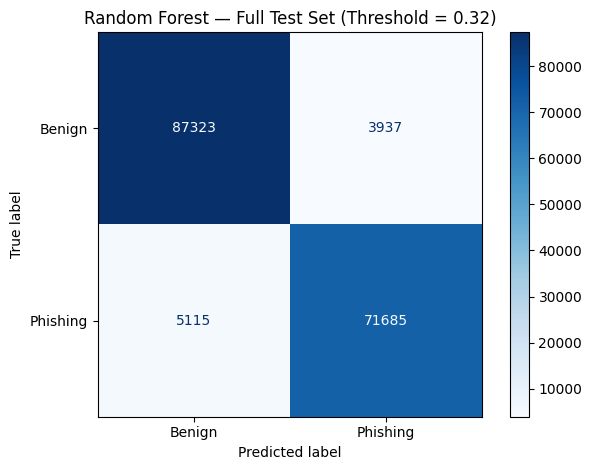

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    rf_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Phishing"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title(
    f"Random Forest — Full Test Set (Threshold = {RF_THRESHOLD})"
)
plt.tight_layout()

# Save BEFORE displaying
plt.savefig(
    MODEL_DIR / "full_random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

gb_results = pd.read_csv(
    MODEL_DIR / "full_dataset_final_test_results.csv"
)

rf_results = pd.read_csv(
    MODEL_DIR / "full_random_forest_test_results.csv"
)

gb_row = gb_results.iloc[0].to_dict()
rf_row = rf_results.iloc[0].to_dict()

comparison = pd.DataFrame([
    {
        "model": "Gradient Boosting",
        "threshold": gb_row["threshold"],
        "accuracy": gb_row["accuracy"],
        "precision": gb_row["precision"],
        "recall": gb_row["recall"],
        "f1": gb_row["f1"],
        "fpr": gb_row["fpr"],
        "false_negatives": gb_row["false_negatives"],
        "false_positives": gb_row["false_positives"]
    },
    {
        "model": "Random Forest",
        "threshold": rf_row["threshold"],
        "accuracy": rf_row["accuracy"],
        "precision": rf_row["precision"],
        "recall": rf_row["recall"],
        "f1": rf_row["f1"],
        "fpr": rf_row["fpr"],
        "false_negatives": rf_row["FN"],
        "false_positives": rf_row["FP"]
    }
])

print("FULL-DATASET TEST COMPARISON")
display(comparison.round(4))

comparison.to_csv(
    MODEL_DIR / "rf_vs_gradient_boosting_full_test.csv",
    index=False
)


FULL-DATASET TEST COMPARISON


,model,threshold,accuracy,precision,recall,f1,fpr,false_negatives,false_positives
0,Gradient Boosting,0.26,0.9392,0.9353,0.9312,0.9333,0.0542,5281.0,4945.0
1,Random Forest,0.32,0.9461,0.9479,0.9334,0.9406,0.0431,5115.0,3937.0
